In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [37]:
df=pd.read_csv('/content/bank.csv')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [39]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [40]:
df.shape

(8912, 17)

In [41]:
df.isnull().sum().sum()

np.int64(513)

In [42]:
df.dropna(axis=0,inplace=True)

In [43]:
df.isnull().sum().sum()

np.int64(0)

In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df.shape

(8719, 17)

In [46]:
df.reset_index(drop=True,inplace=True)

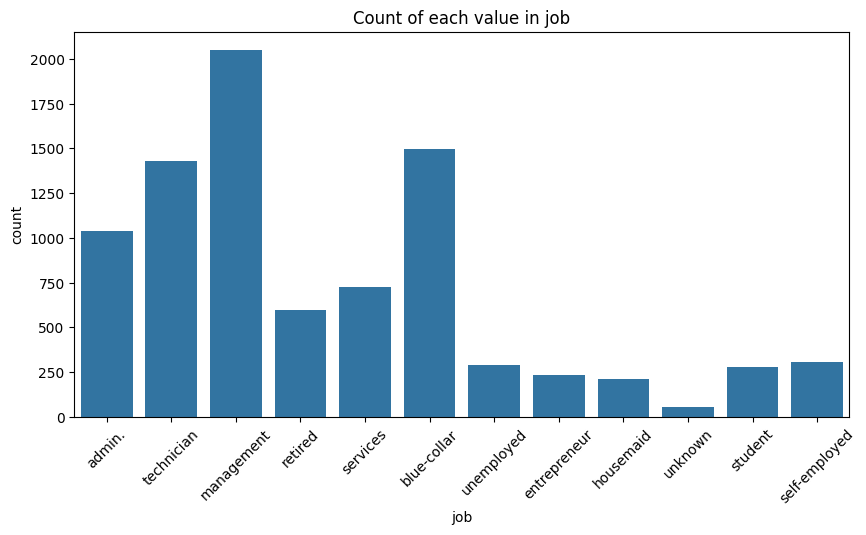

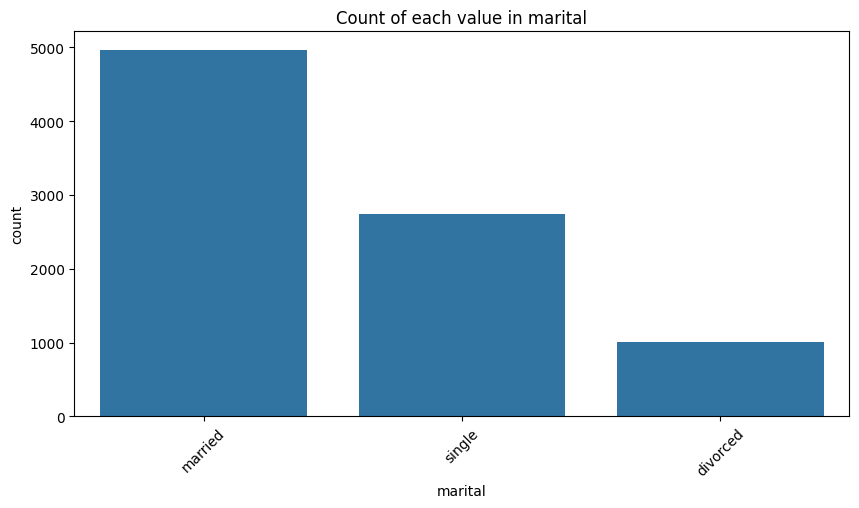

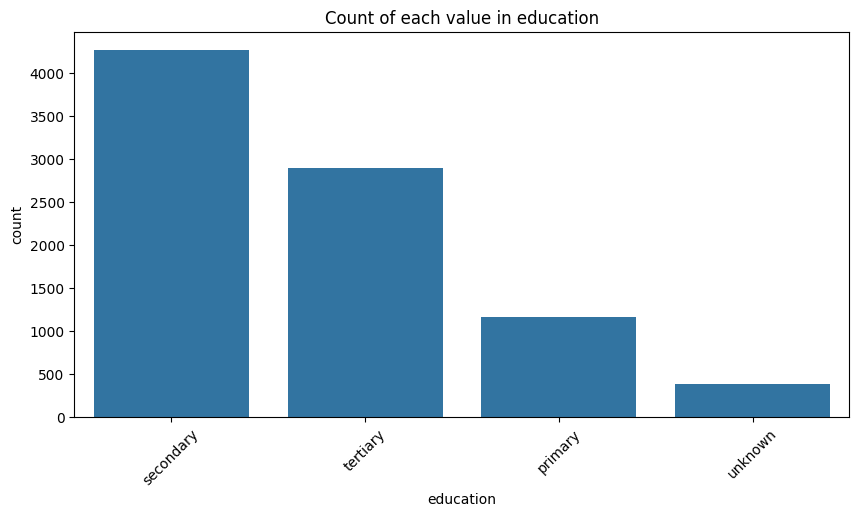

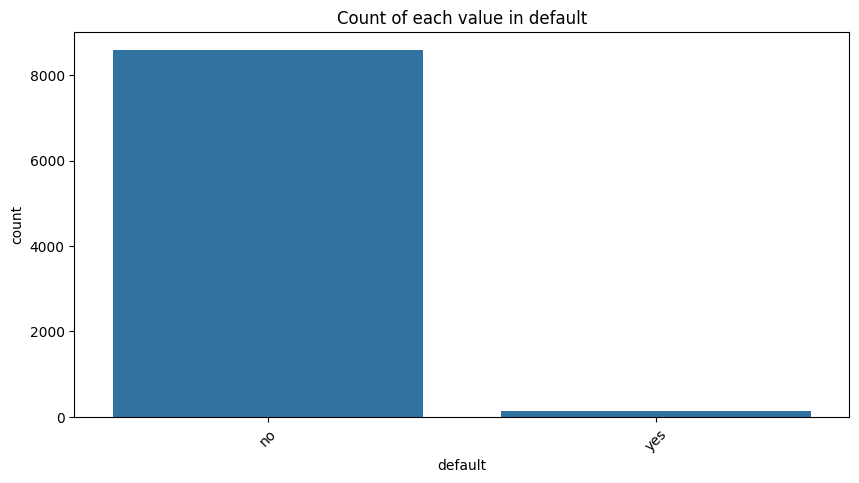

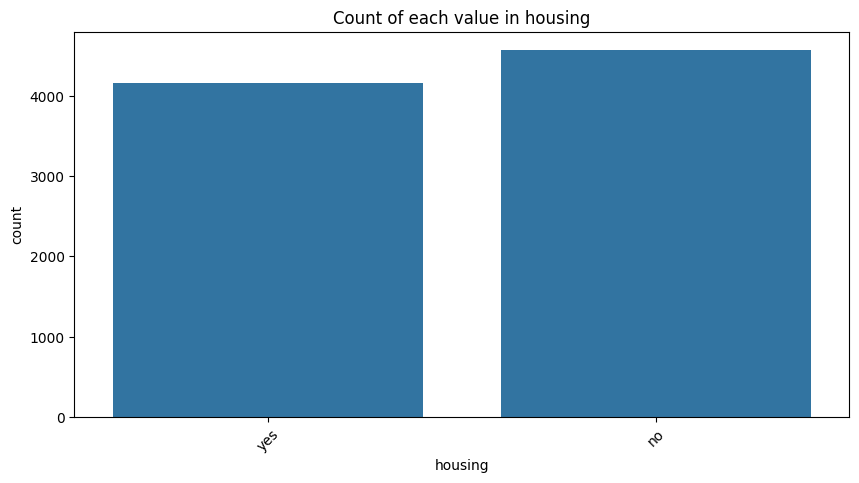

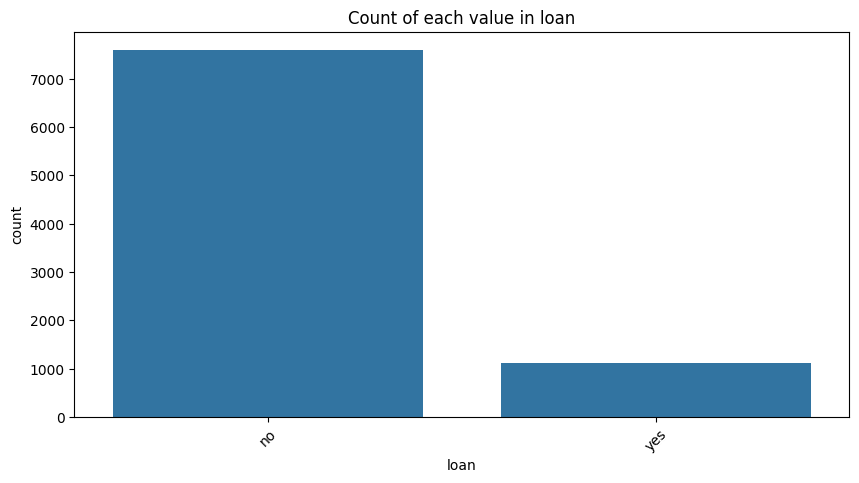

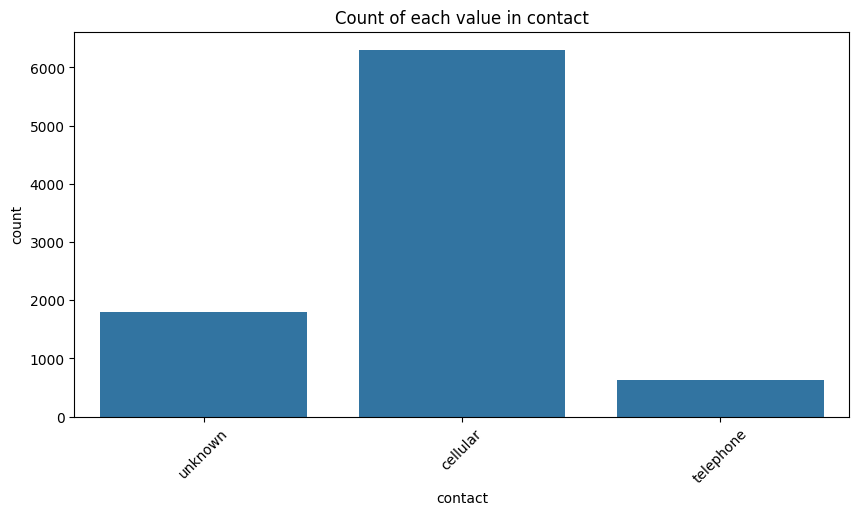

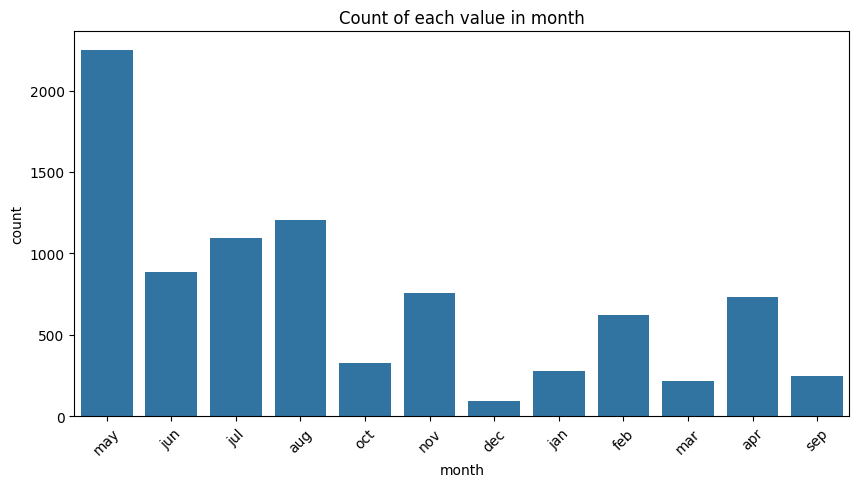

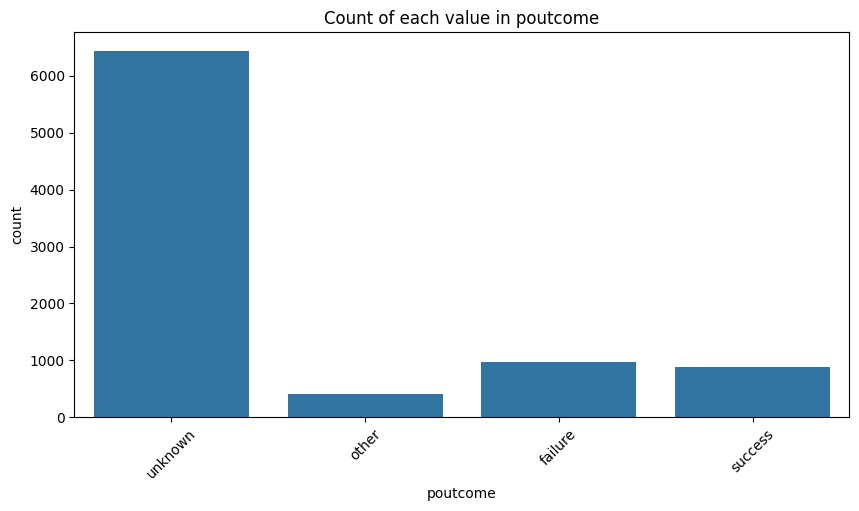

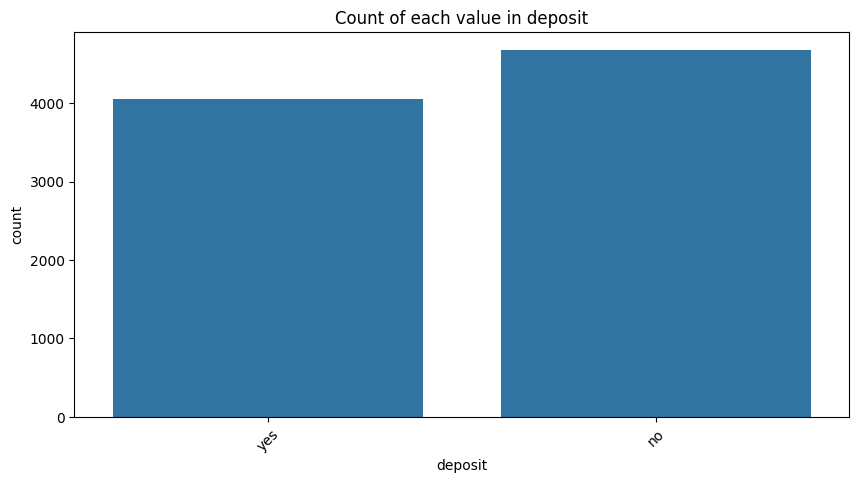

In [47]:
cat=df.select_dtypes(include='object')

for col in cat:
    plt.figure(figsize=(10, 5))

    sns.countplot(data=df, x=col)

    plt.title(f'Count of each value in {col}')
    plt.xticks(rotation=45)
    plt.show()

In [48]:
df.drop(columns=['poutcome'],inplace=True)

In [49]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,yes


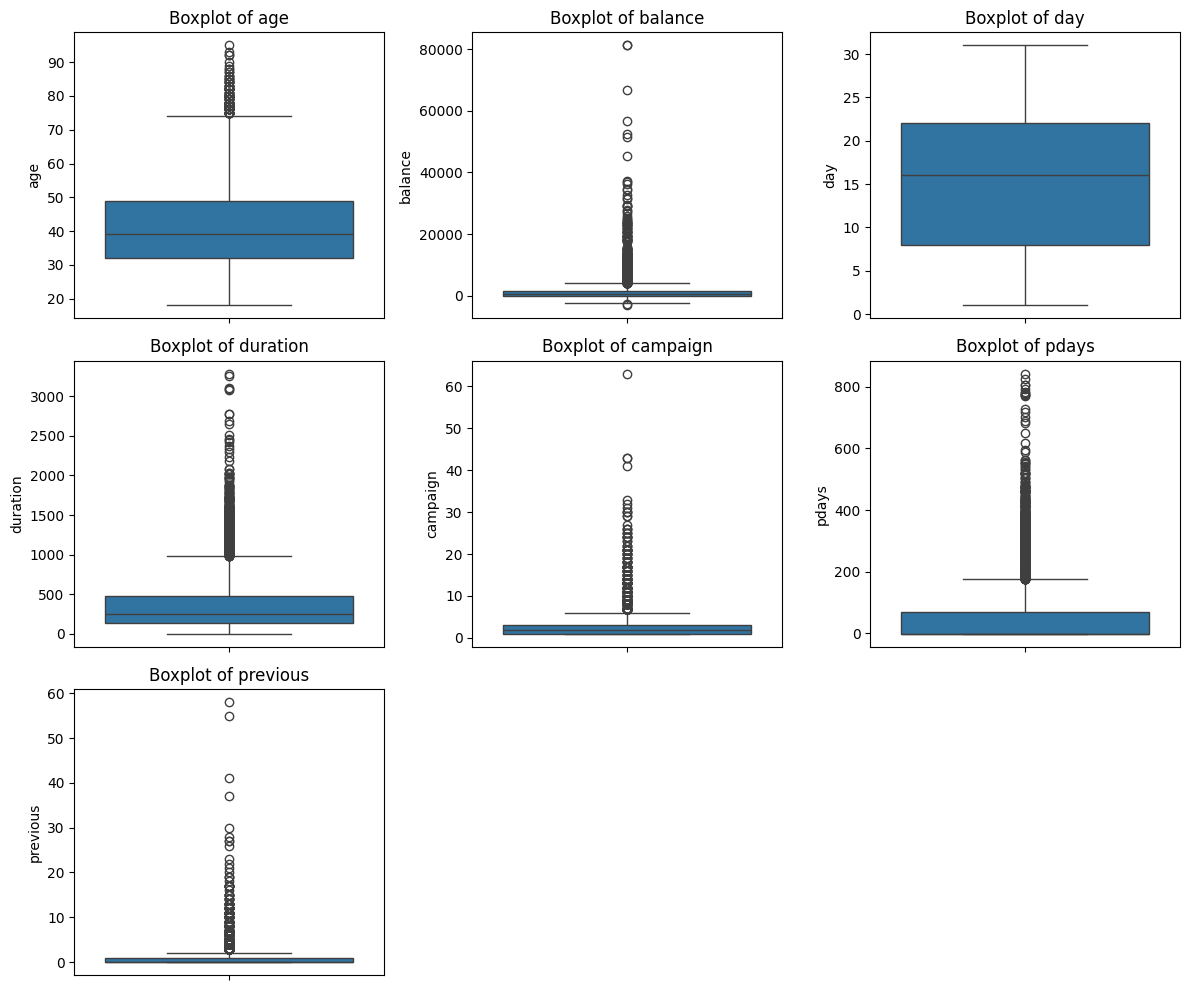

In [50]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(12, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

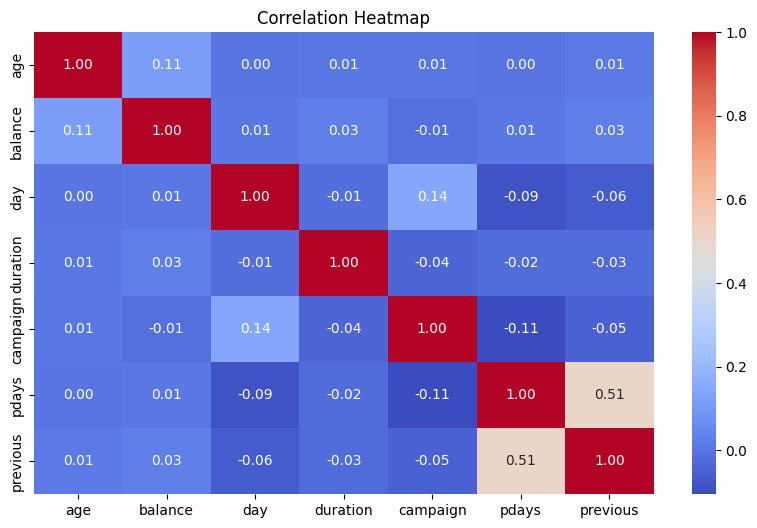

In [51]:


numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


In [ ]:


for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.show()


In [ ]:
df.describe()

In [ ]:
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[
      (df[col] < lower) |
      (df[col] > upper)
  ]


  print("Number of Outliers:", len(outliers))

In [ ]:
df.shape

In [ ]:
df.head()

In [ ]:
x=df.drop('deposit',axis=1)
y=df['deposit']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.1, random_state=42
)

In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
cat=x_train.select_dtypes(include='object')
for col in cat:
  x_train[col]=le.fit_transform(x_train[col])
  x_test[col]=le.transform(x_test[col])
  y_train=le.fit_transform(y_train)
  y_test=le.transform(y_test)


In [ ]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [ ]:
pip install xgboost lightgbm catboost

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [ ]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [ ]:
from tqdm import tqdm

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[388  84]
 [ 89 311]]


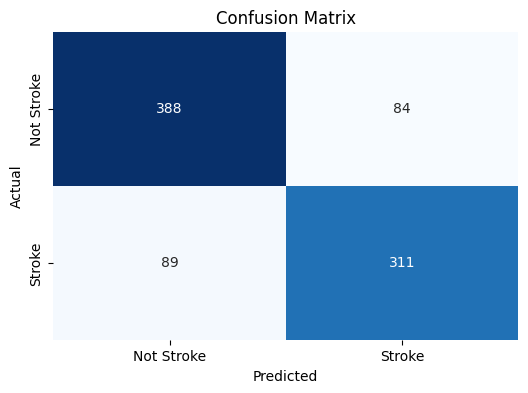


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.81      0.82      0.82       472
      Stroke       0.79      0.78      0.78       400

    accuracy                           0.80       872
   macro avg       0.80      0.80      0.80       872
weighted avg       0.80      0.80      0.80       872

ROC-AUC: 0.8674099576271187


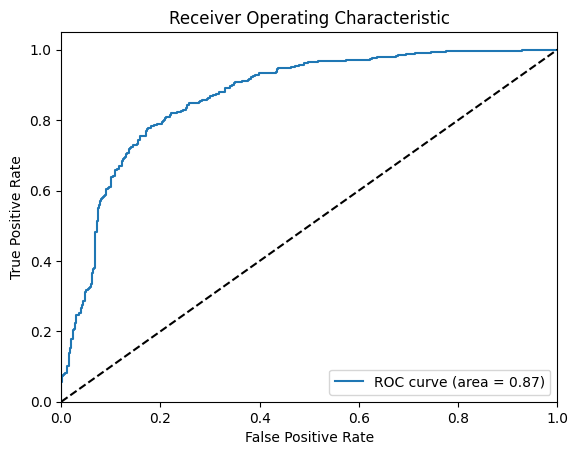

PR AUC: 0.8207751670652249


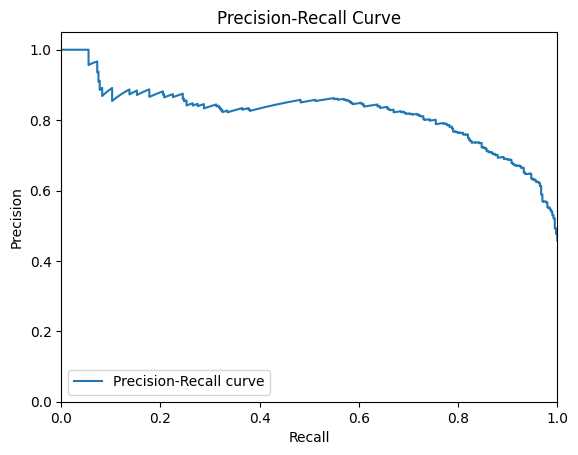

  8%|▊         | 1/13 [00:00<00:05,  2.23it/s]


Confusion Matrix:
 [[386  86]
 [107 293]]


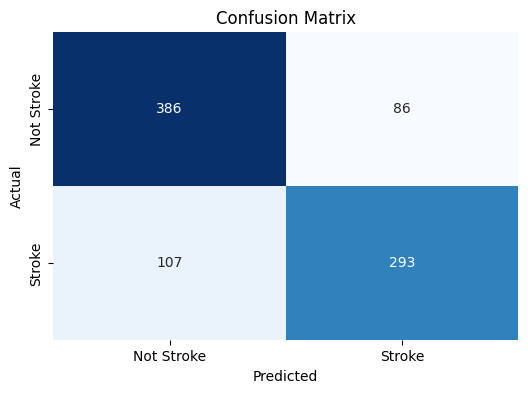


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.78      0.82      0.80       472
      Stroke       0.77      0.73      0.75       400

    accuracy                           0.78       872
   macro avg       0.78      0.78      0.78       872
weighted avg       0.78      0.78      0.78       872

ROC-AUC: 0.8550820974576272


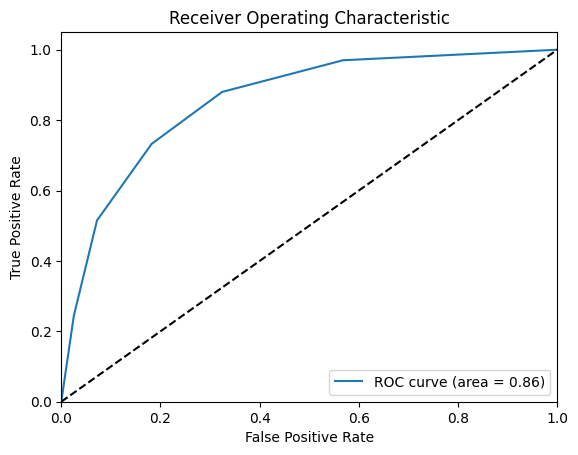

PR AUC: 0.7879742216625505


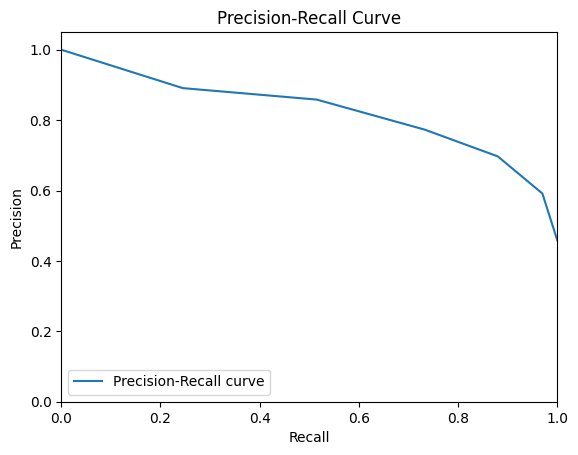

 15%|█▌        | 2/13 [00:04<00:26,  2.44s/it]


Confusion Matrix:
 [[370 102]
 [ 63 337]]


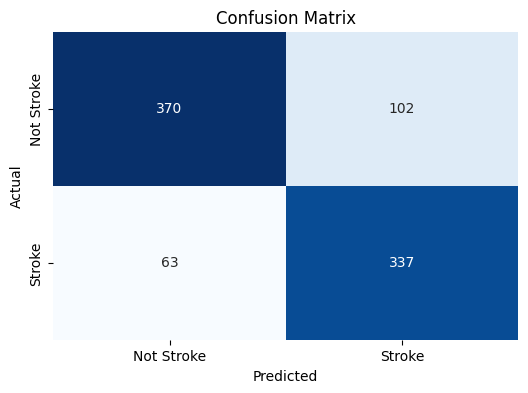


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.78      0.82       472
      Stroke       0.77      0.84      0.80       400

    accuracy                           0.81       872
   macro avg       0.81      0.81      0.81       872
weighted avg       0.81      0.81      0.81       872

ROC-AUC: 0.8975635593220339


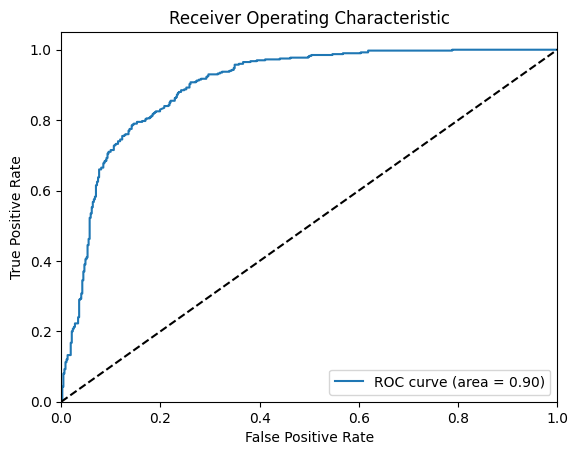

PR AUC: 0.8458371381023921


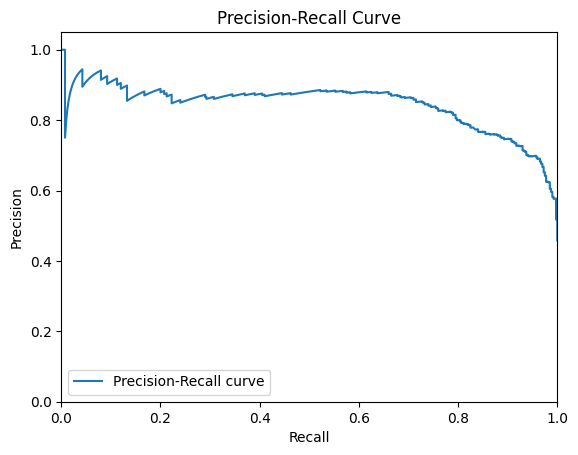

 23%|██▎       | 3/13 [00:19<01:22,  8.29s/it]


Confusion Matrix:
 [[378  94]
 [ 93 307]]


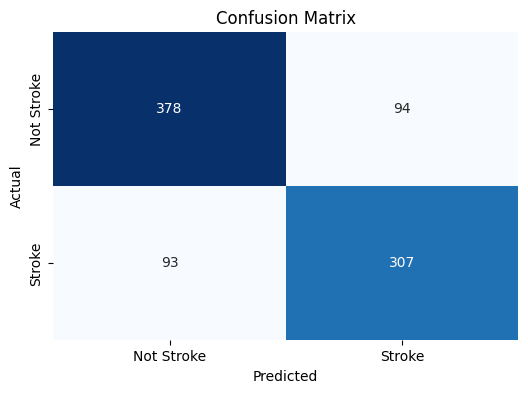


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.80      0.80       472
      Stroke       0.77      0.77      0.77       400

    accuracy                           0.79       872
   macro avg       0.78      0.78      0.78       872
weighted avg       0.79      0.79      0.79       872

ROC-AUC: 0.7841737288135593


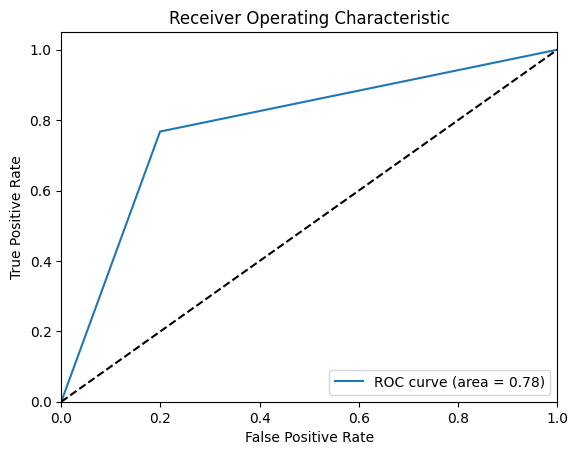

PR AUC: 0.6942386579423001


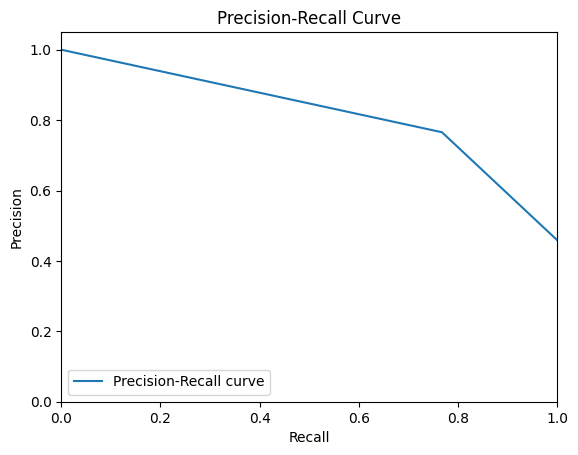

 31%|███       | 4/13 [00:20<00:46,  5.20s/it]


Confusion Matrix:
 [[315 157]
 [ 62 338]]


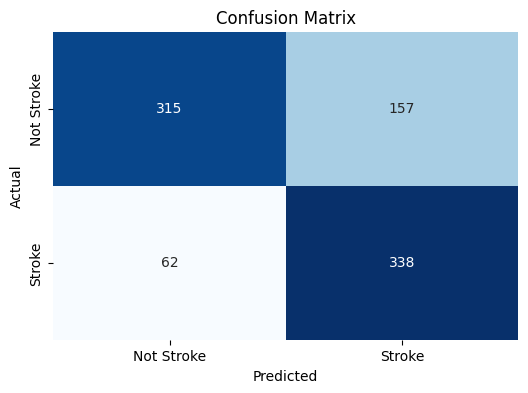


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.67      0.74       472
      Stroke       0.68      0.84      0.76       400

    accuracy                           0.75       872
   macro avg       0.76      0.76      0.75       872
weighted avg       0.77      0.75      0.75       872

ROC-AUC: 0.8190121822033897


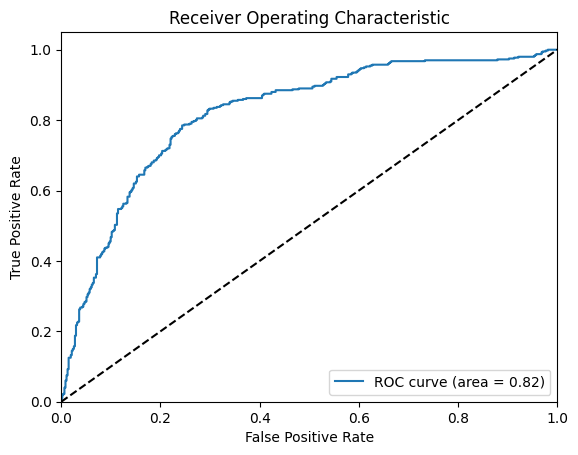

PR AUC: 0.7666599985848489


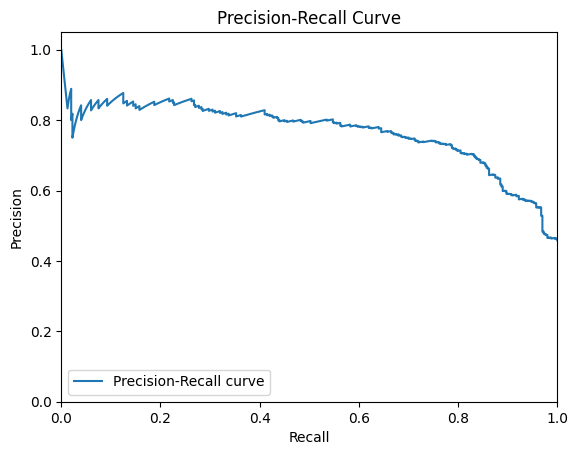

 38%|███▊      | 5/13 [00:20<00:27,  3.48s/it]


Confusion Matrix:
 [[390  82]
 [ 40 360]]


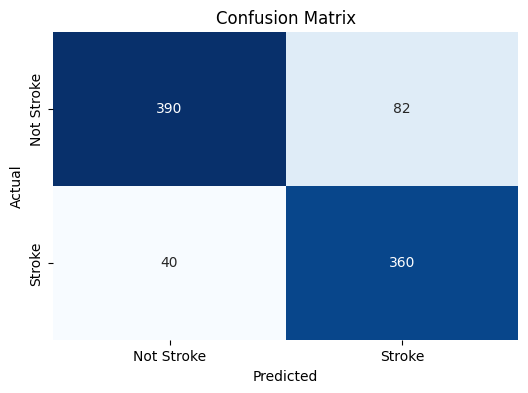


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.83      0.86       472
      Stroke       0.81      0.90      0.86       400

    accuracy                           0.86       872
   macro avg       0.86      0.86      0.86       872
weighted avg       0.86      0.86      0.86       872

ROC-AUC: 0.9307997881355932


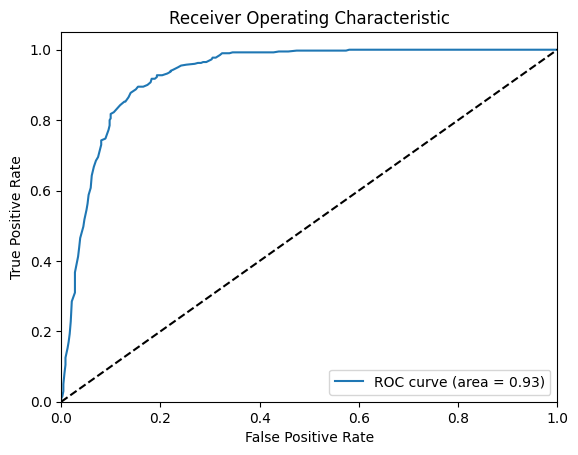

PR AUC: 0.8843423080173092


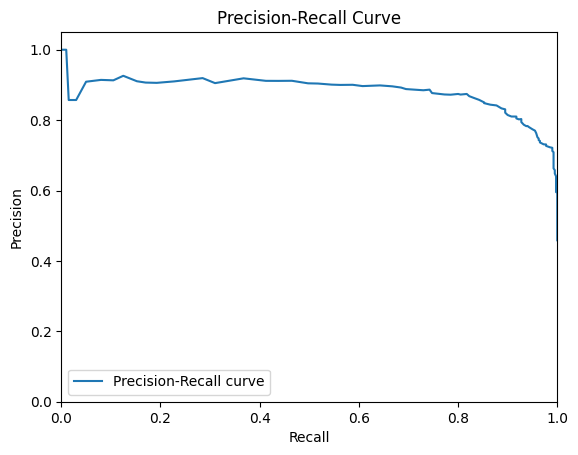

 46%|████▌     | 6/13 [00:22<00:20,  2.97s/it]


Confusion Matrix:
 [[403  69]
 [ 54 346]]


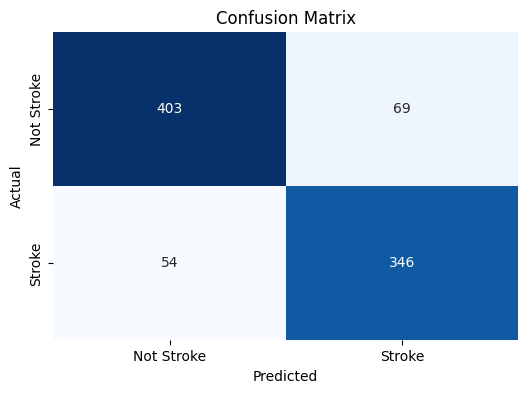


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.85      0.87       472
      Stroke       0.83      0.86      0.85       400

    accuracy                           0.86       872
   macro avg       0.86      0.86      0.86       872
weighted avg       0.86      0.86      0.86       872

ROC-AUC: 0.9189459745762711


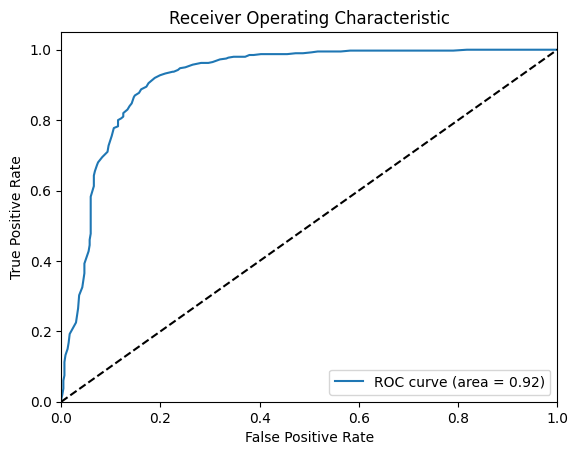

PR AUC: 0.8653272165285256


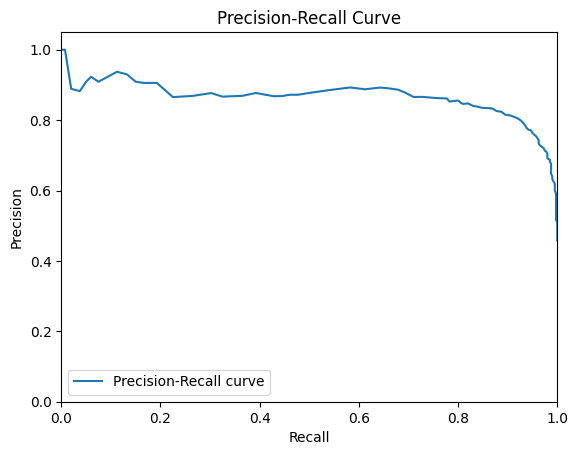

 54%|█████▍    | 7/13 [00:24<00:15,  2.54s/it]


Confusion Matrix:
 [[381  91]
 [ 74 326]]


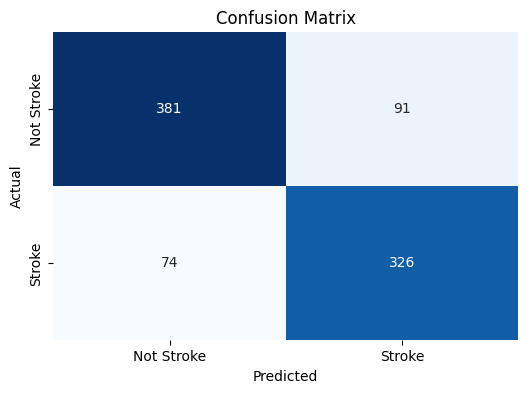


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.81      0.82       472
      Stroke       0.78      0.81      0.80       400

    accuracy                           0.81       872
   macro avg       0.81      0.81      0.81       872
weighted avg       0.81      0.81      0.81       872

ROC-AUC: 0.8900794491525423


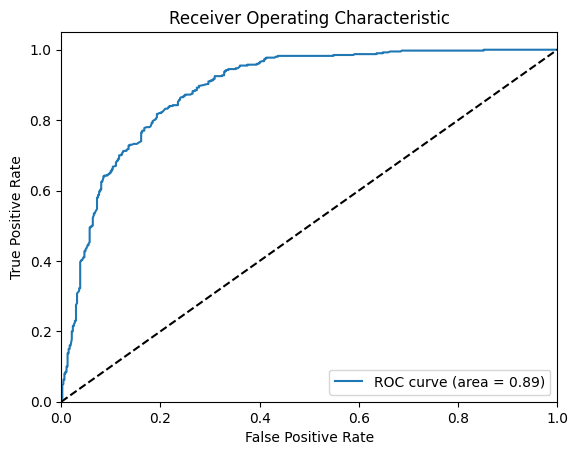

PR AUC: 0.8403921879897455


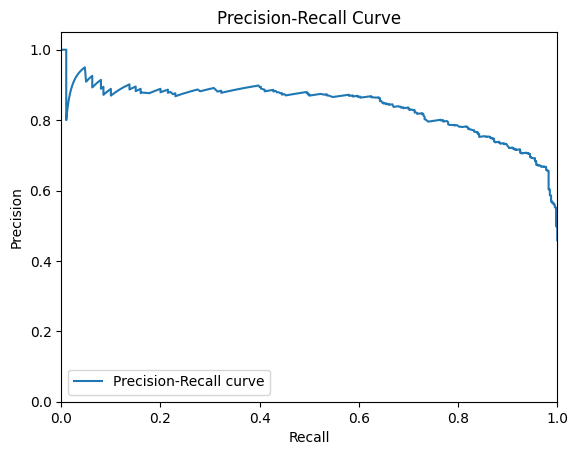

 62%|██████▏   | 8/13 [00:24<00:10,  2.02s/it]


Confusion Matrix:
 [[387  85]
 [ 44 356]]


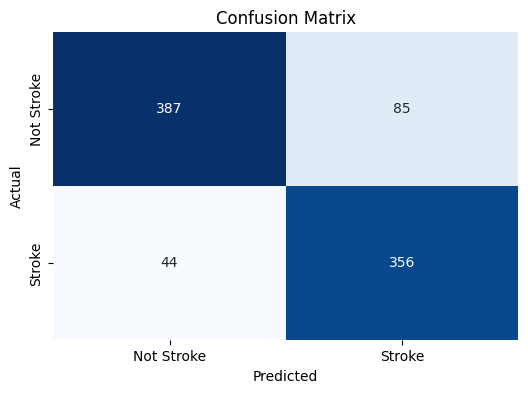


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.82      0.86       472
      Stroke       0.81      0.89      0.85       400

    accuracy                           0.85       872
   macro avg       0.85      0.85      0.85       872
weighted avg       0.86      0.85      0.85       872

ROC-AUC: 0.9230667372881356


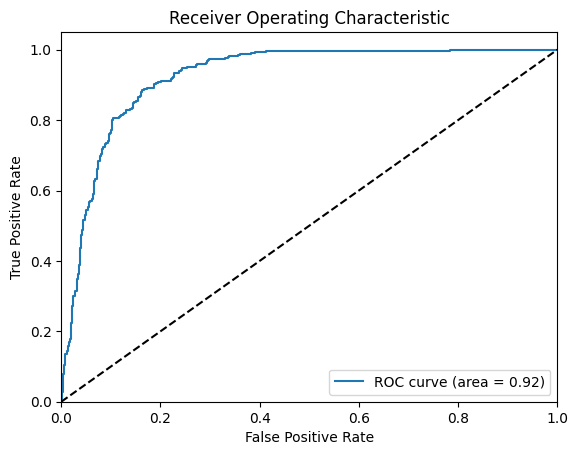

PR AUC: 0.8761696058374066


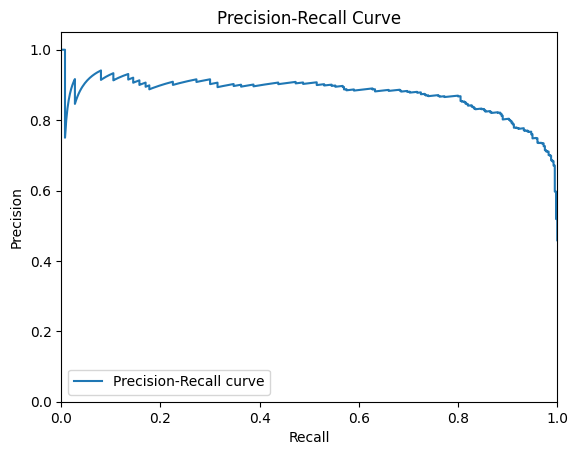

 69%|██████▉   | 9/13 [00:27<00:08,  2.05s/it]


Confusion Matrix:
 [[398  74]
 [ 37 363]]


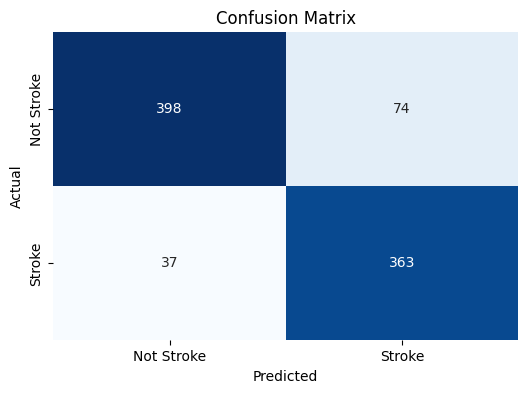


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.84      0.88       472
      Stroke       0.83      0.91      0.87       400

    accuracy                           0.87       872
   macro avg       0.87      0.88      0.87       872
weighted avg       0.88      0.87      0.87       872

ROC-AUC: 0.9327383474576272


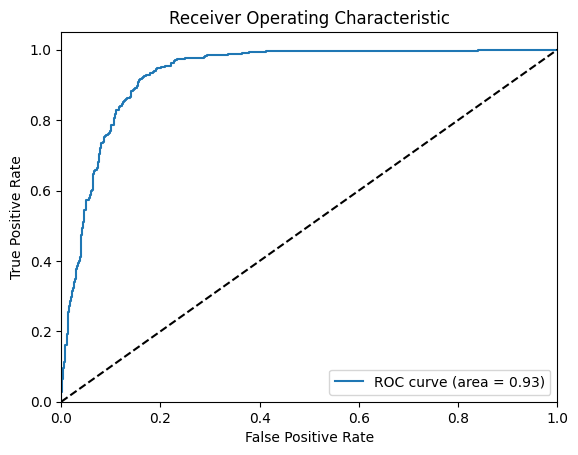

PR AUC: 0.8944558975502337


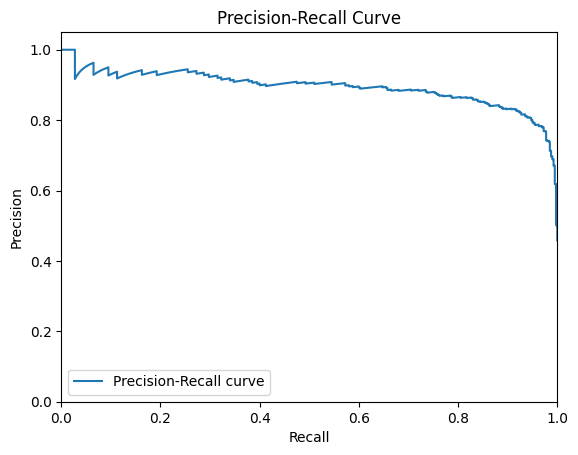

 77%|███████▋  | 10/13 [00:28<00:05,  1.73s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [23:04:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[397  75]
 [ 39 361]]


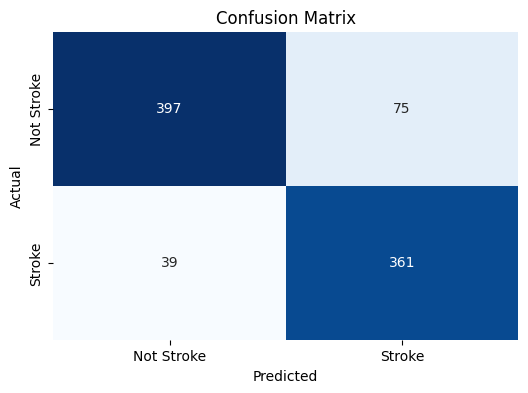


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.84      0.87       472
      Stroke       0.83      0.90      0.86       400

    accuracy                           0.87       872
   macro avg       0.87      0.87      0.87       872
weighted avg       0.87      0.87      0.87       872

ROC-AUC: 0.9291472457627119


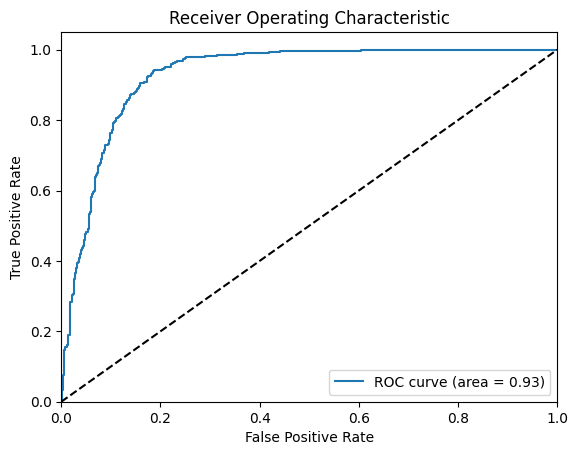

PR AUC: 0.8810732363295559


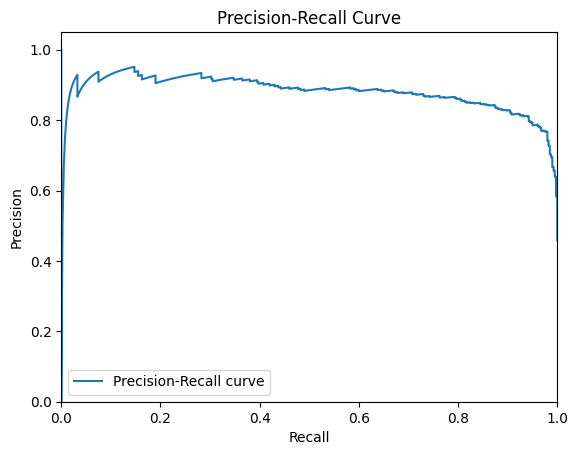

 85%|████████▍ | 11/13 [00:29<00:03,  1.55s/it]


Confusion Matrix:
 [[402  70]
 [ 35 365]]


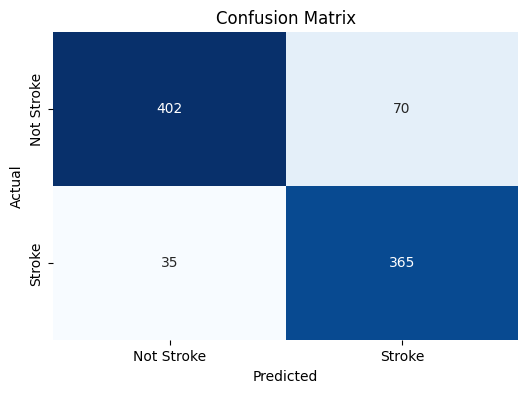


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.92      0.85      0.88       472
      Stroke       0.84      0.91      0.87       400

    accuracy                           0.88       872
   macro avg       0.88      0.88      0.88       872
weighted avg       0.88      0.88      0.88       872

ROC-AUC: 0.937155720338983


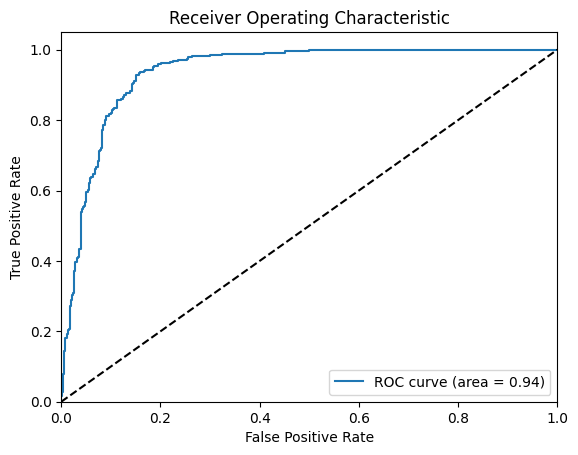

PR AUC: 0.8962747024442482


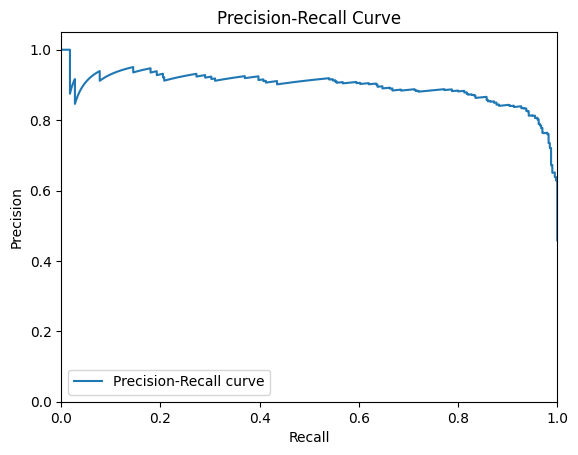

 92%|█████████▏| 12/13 [00:34<00:02,  2.80s/it]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 3646, number of negative: 4201
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001166 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 970
[LightGBM] [Info] Number of data points in the train set: 7847, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.464636 -> initscore=-0.141692
[LightGBM] [Info] Start training from score -0.141692

Confusion Matrix:
 [[400  72]
 [ 34 366]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


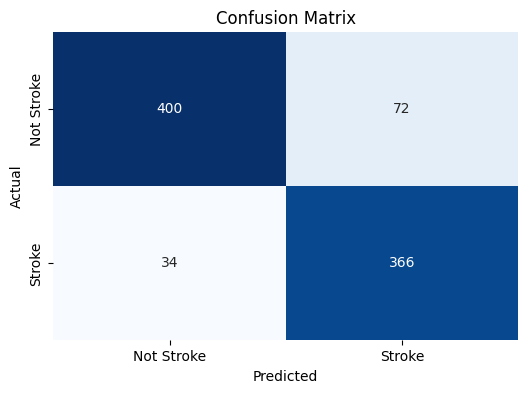

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.92      0.85      0.88       472
      Stroke       0.84      0.92      0.87       400

    accuracy                           0.88       872
   macro avg       0.88      0.88      0.88       872
weighted avg       0.88      0.88      0.88       872

ROC-AUC: 0.9352012711864407


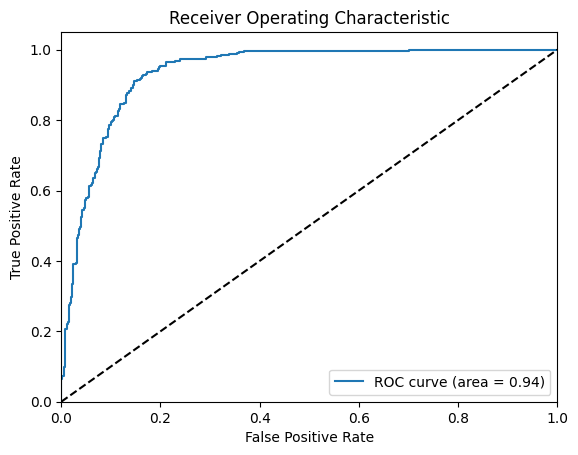

PR AUC: 0.9004914837417479


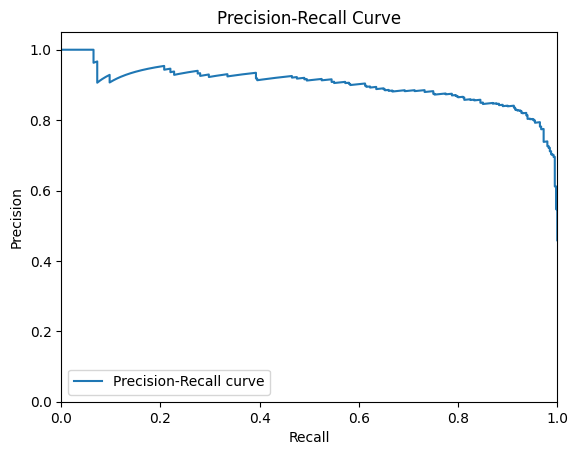

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[388  84]
 [ 89 311]]


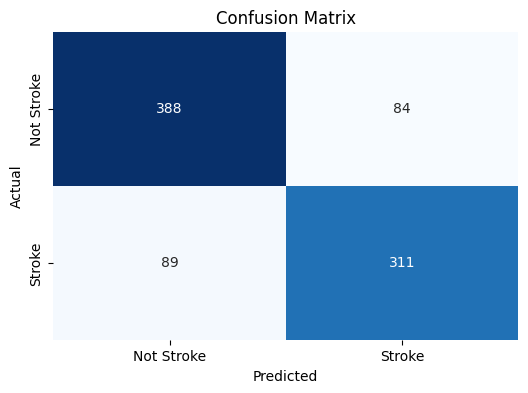


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.81      0.82      0.82       472
      Stroke       0.79      0.78      0.78       400

    accuracy                           0.80       872
   macro avg       0.80      0.80      0.80       872
weighted avg       0.80      0.80      0.80       872

ROC-AUC: 0.8674099576271187


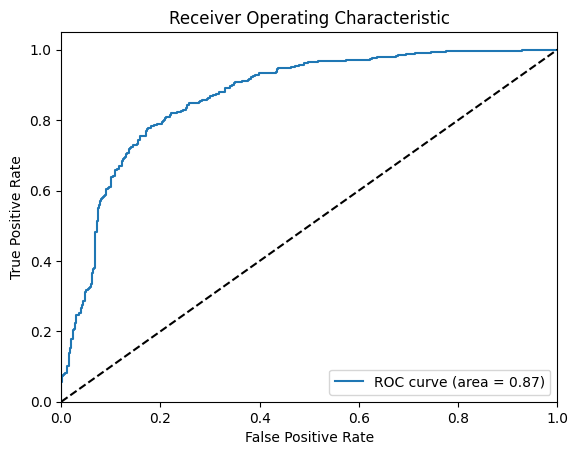

PR AUC: 0.8207751670652249


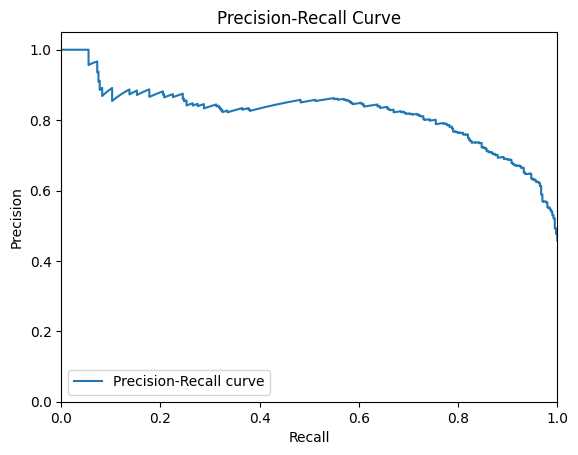

  8%|▊         | 1/13 [00:00<00:06,  1.90it/s]


Confusion Matrix:
 [[386  86]
 [107 293]]


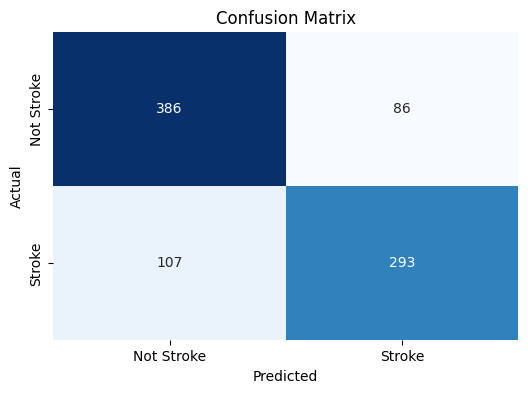


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.78      0.82      0.80       472
      Stroke       0.77      0.73      0.75       400

    accuracy                           0.78       872
   macro avg       0.78      0.78      0.78       872
weighted avg       0.78      0.78      0.78       872

ROC-AUC: 0.8550820974576272


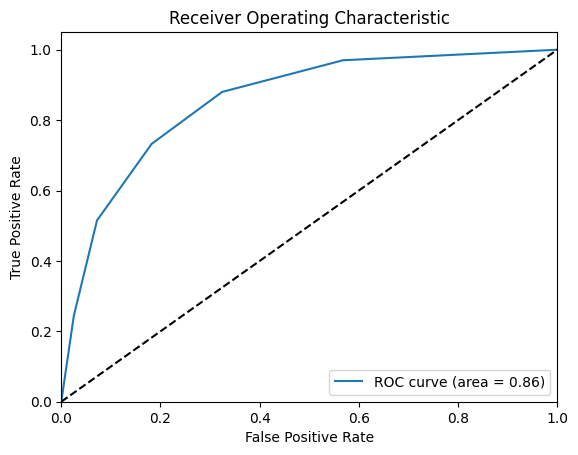

PR AUC: 0.7879742216625505


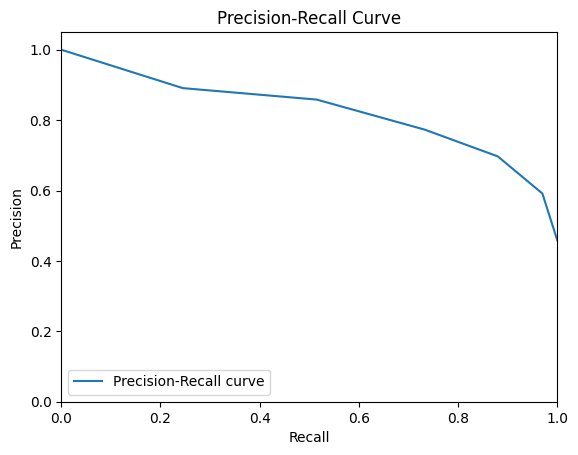

 15%|█▌        | 2/13 [00:02<00:17,  1.59s/it]


Confusion Matrix:
 [[370 102]
 [ 63 337]]


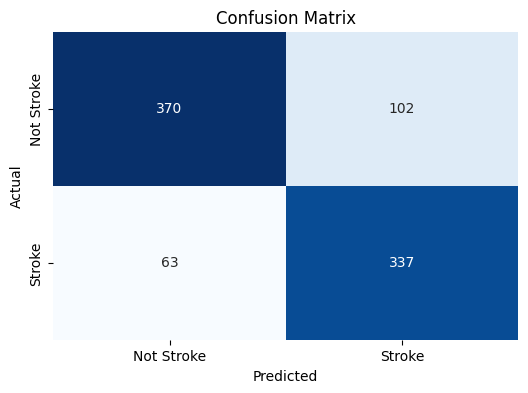


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.78      0.82       472
      Stroke       0.77      0.84      0.80       400

    accuracy                           0.81       872
   macro avg       0.81      0.81      0.81       872
weighted avg       0.81      0.81      0.81       872

ROC-AUC: 0.8975635593220339


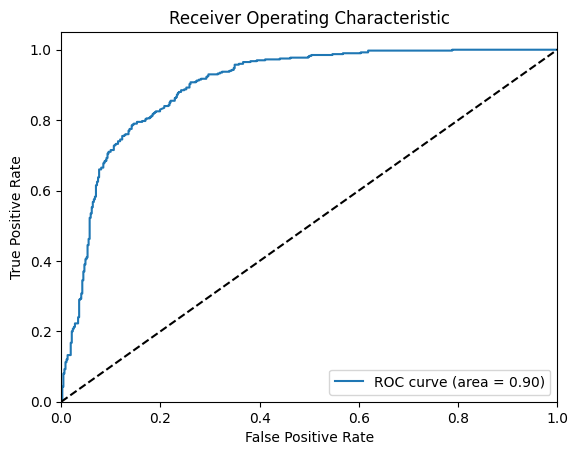

PR AUC: 0.8458371381023921


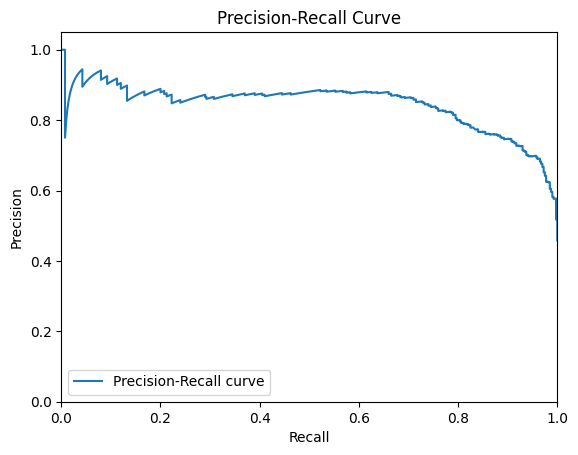

 23%|██▎       | 3/13 [00:18<01:19,  7.95s/it]


Confusion Matrix:
 [[378  94]
 [ 93 307]]


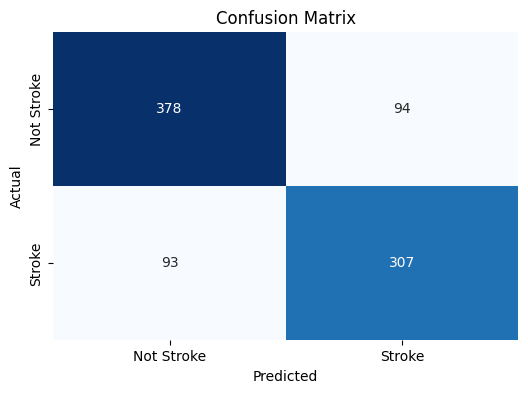


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.80      0.80       472
      Stroke       0.77      0.77      0.77       400

    accuracy                           0.79       872
   macro avg       0.78      0.78      0.78       872
weighted avg       0.79      0.79      0.79       872

ROC-AUC: 0.7841737288135593


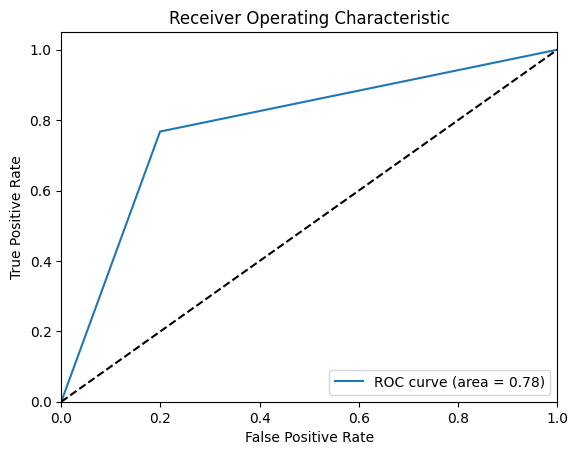

PR AUC: 0.6942386579423001


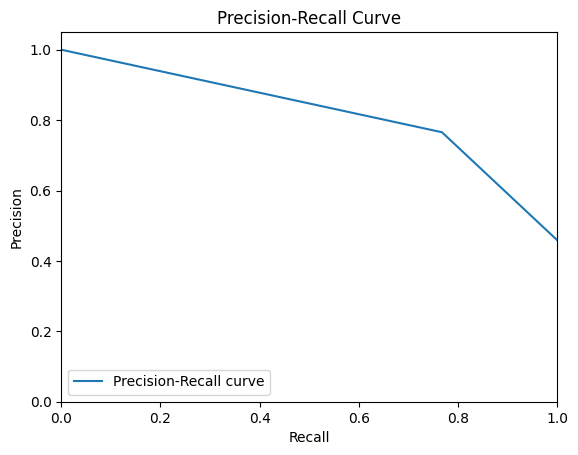

 31%|███       | 4/13 [00:18<00:45,  5.02s/it]


Confusion Matrix:
 [[315 157]
 [ 62 338]]


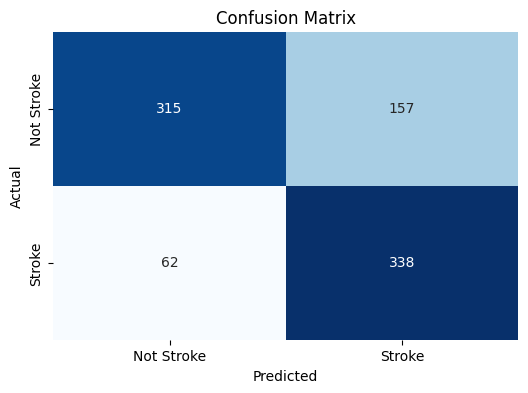


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.67      0.74       472
      Stroke       0.68      0.84      0.76       400

    accuracy                           0.75       872
   macro avg       0.76      0.76      0.75       872
weighted avg       0.77      0.75      0.75       872

ROC-AUC: 0.8190121822033897


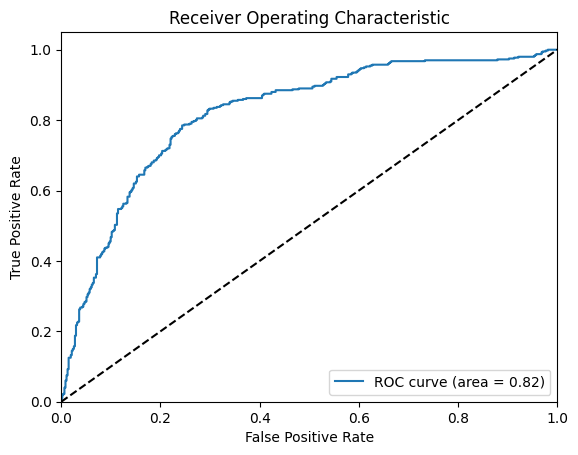

PR AUC: 0.7666599985848489


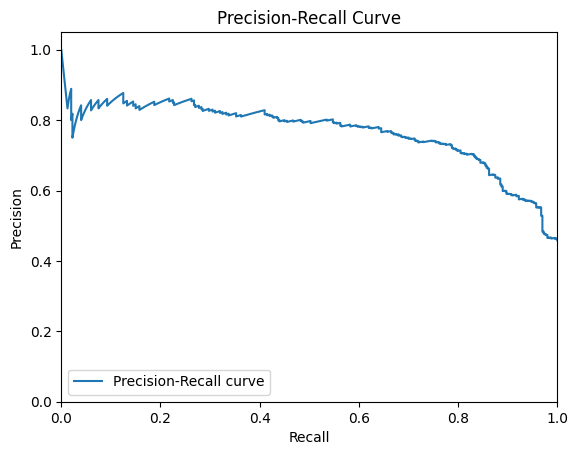

 38%|███▊      | 5/13 [00:19<00:27,  3.39s/it]


Confusion Matrix:
 [[390  82]
 [ 40 360]]


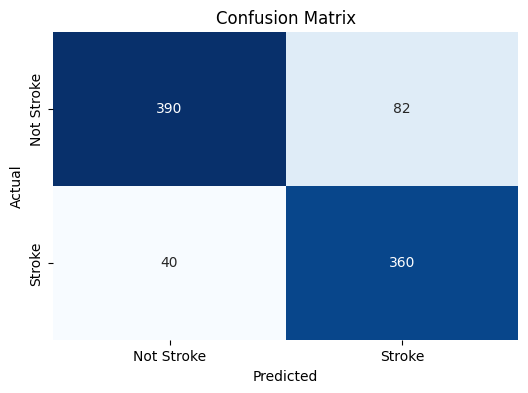


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.83      0.86       472
      Stroke       0.81      0.90      0.86       400

    accuracy                           0.86       872
   macro avg       0.86      0.86      0.86       872
weighted avg       0.86      0.86      0.86       872

ROC-AUC: 0.9307997881355932


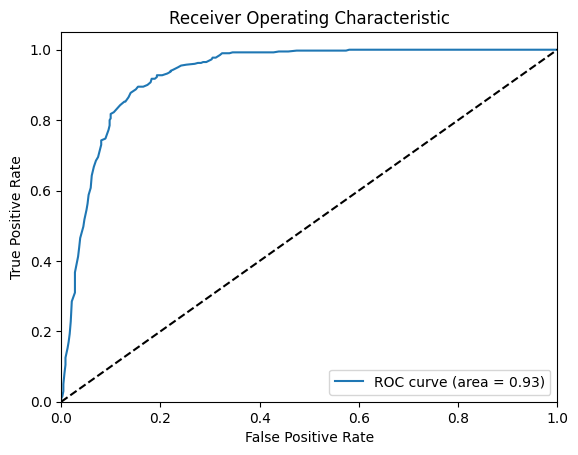

PR AUC: 0.8843423080173092


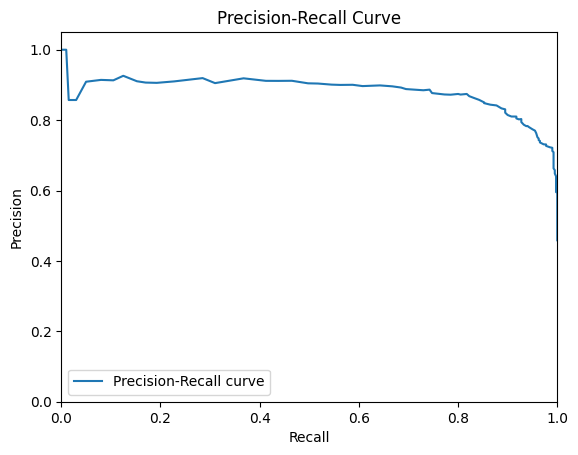

 46%|████▌     | 6/13 [00:21<00:21,  3.12s/it]


Confusion Matrix:
 [[403  69]
 [ 54 346]]


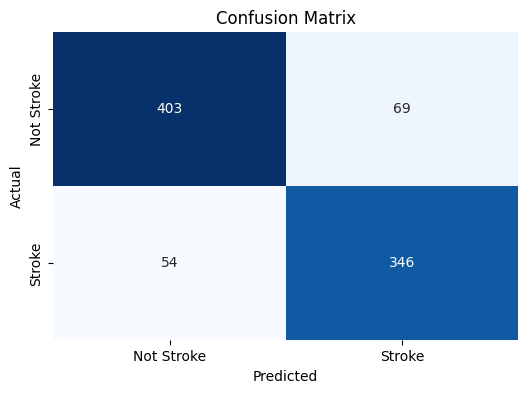


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.85      0.87       472
      Stroke       0.83      0.86      0.85       400

    accuracy                           0.86       872
   macro avg       0.86      0.86      0.86       872
weighted avg       0.86      0.86      0.86       872

ROC-AUC: 0.9189459745762711


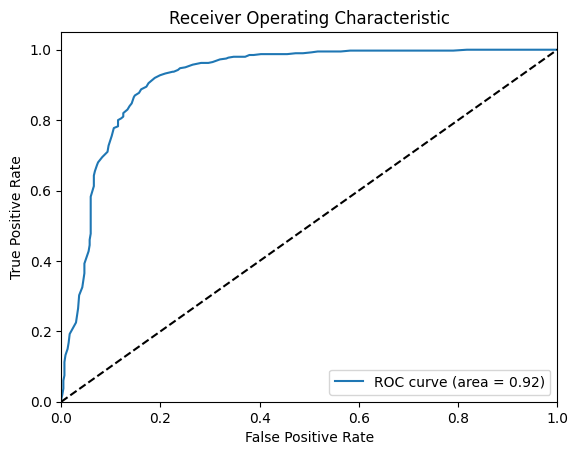

PR AUC: 0.8653272165285256


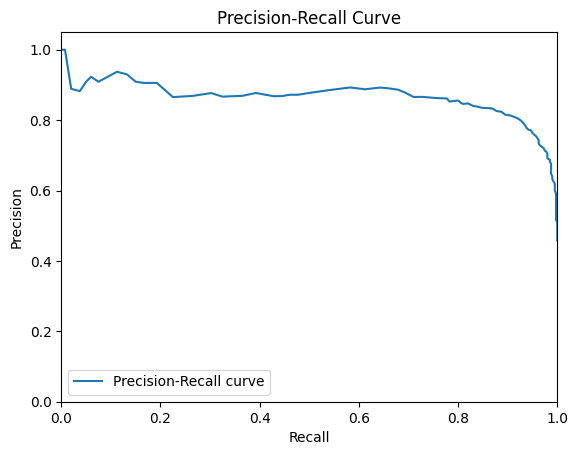

 54%|█████▍    | 7/13 [00:24<00:17,  2.85s/it]


Confusion Matrix:
 [[381  91]
 [ 74 326]]


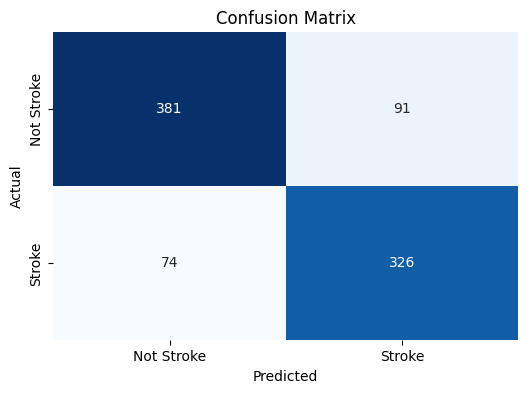


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.81      0.82       472
      Stroke       0.78      0.81      0.80       400

    accuracy                           0.81       872
   macro avg       0.81      0.81      0.81       872
weighted avg       0.81      0.81      0.81       872

ROC-AUC: 0.8900794491525423


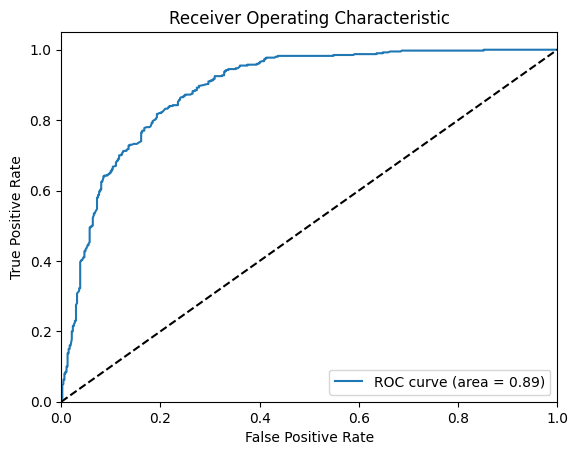

PR AUC: 0.8403921879897455


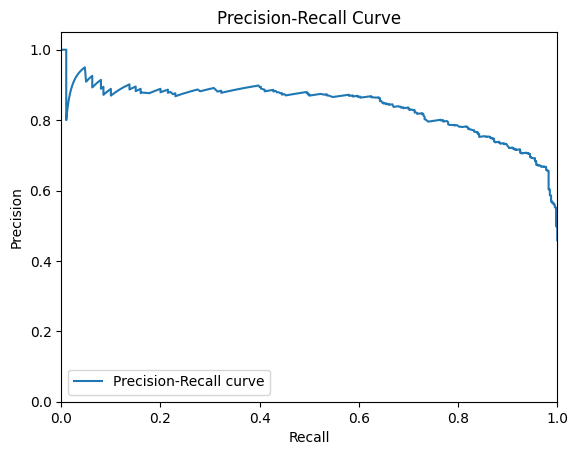

 62%|██████▏   | 8/13 [00:25<00:11,  2.26s/it]


Confusion Matrix:
 [[387  85]
 [ 44 356]]


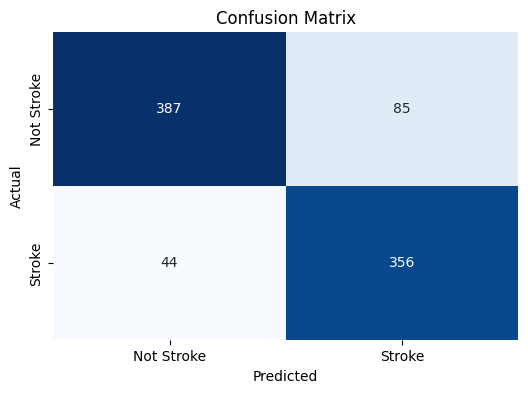


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.82      0.86       472
      Stroke       0.81      0.89      0.85       400

    accuracy                           0.85       872
   macro avg       0.85      0.85      0.85       872
weighted avg       0.86      0.85      0.85       872

ROC-AUC: 0.9230667372881356


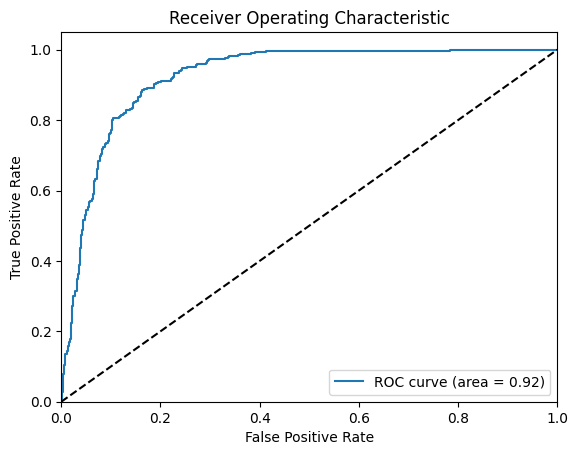

PR AUC: 0.8761696058374066


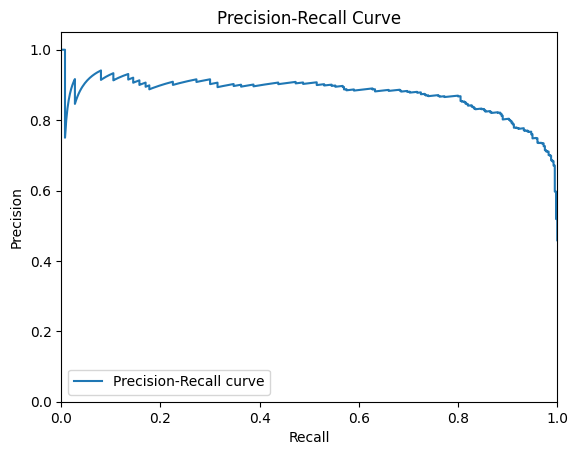

 69%|██████▉   | 9/13 [00:27<00:08,  2.23s/it]


Confusion Matrix:
 [[398  74]
 [ 37 363]]


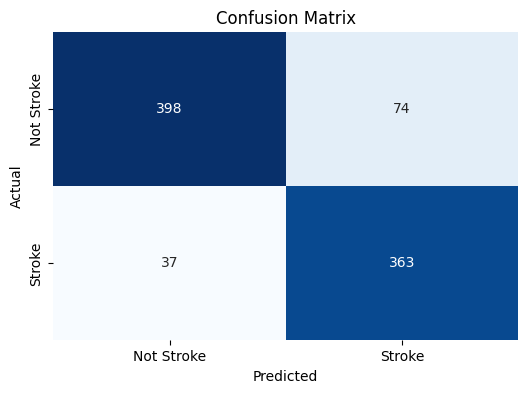


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.84      0.88       472
      Stroke       0.83      0.91      0.87       400

    accuracy                           0.87       872
   macro avg       0.87      0.88      0.87       872
weighted avg       0.88      0.87      0.87       872

ROC-AUC: 0.9327383474576272


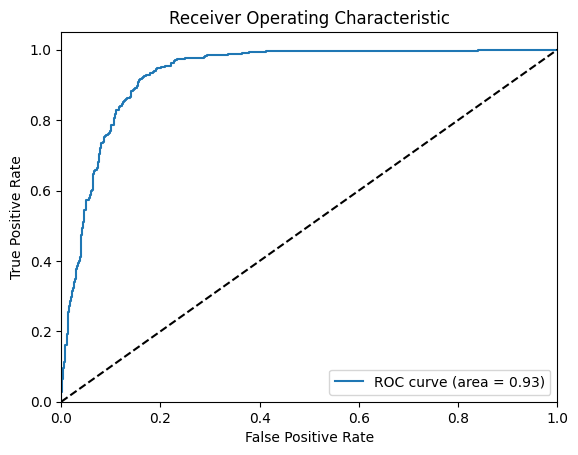

PR AUC: 0.8944558975502337


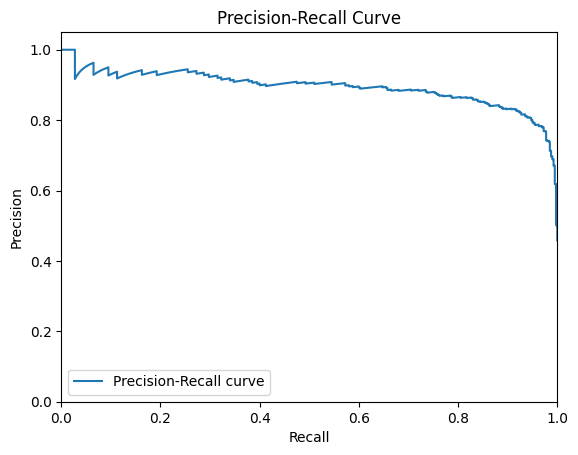

 77%|███████▋  | 10/13 [00:28<00:05,  1.84s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [23:04:47] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[397  75]
 [ 39 361]]


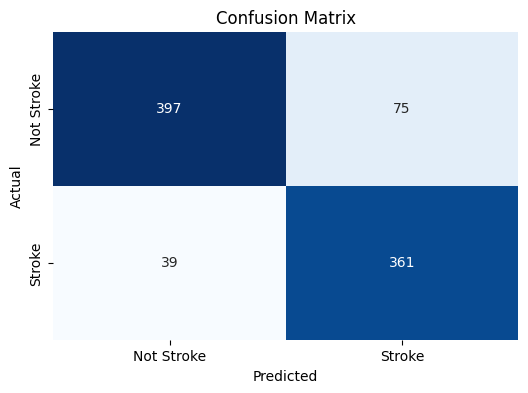


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.84      0.87       472
      Stroke       0.83      0.90      0.86       400

    accuracy                           0.87       872
   macro avg       0.87      0.87      0.87       872
weighted avg       0.87      0.87      0.87       872

ROC-AUC: 0.9291472457627119


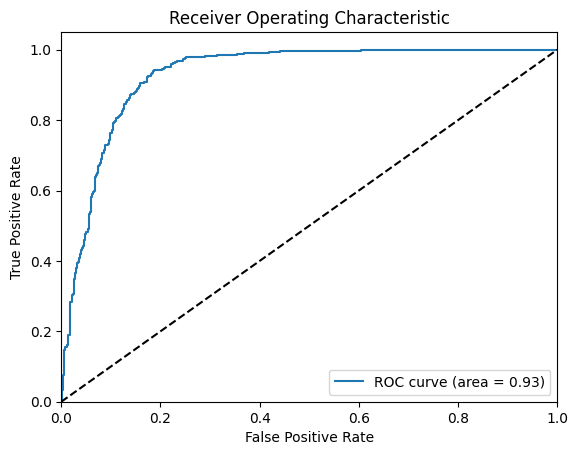

PR AUC: 0.8810732363295559


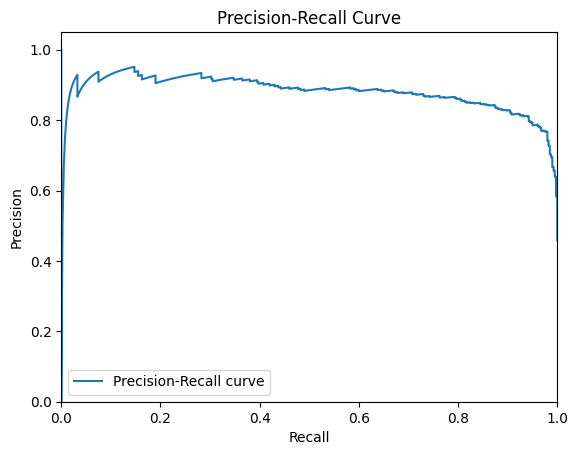

 85%|████████▍ | 11/13 [00:29<00:03,  1.52s/it]


Confusion Matrix:
 [[402  70]
 [ 35 365]]


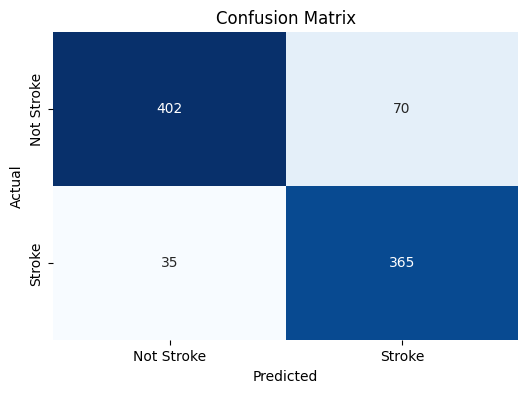


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.92      0.85      0.88       472
      Stroke       0.84      0.91      0.87       400

    accuracy                           0.88       872
   macro avg       0.88      0.88      0.88       872
weighted avg       0.88      0.88      0.88       872

ROC-AUC: 0.937155720338983


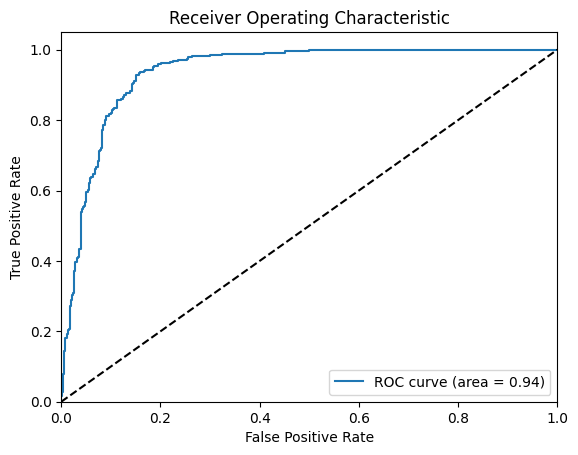

PR AUC: 0.8962747024442482


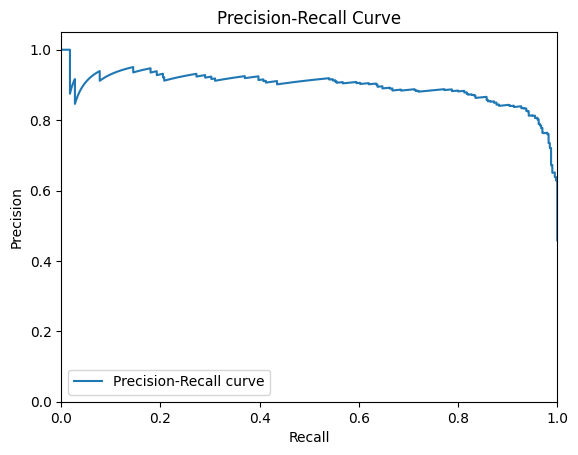

 92%|█████████▏| 12/13 [00:34<00:02,  2.60s/it]

[LightGBM] [Info] Number of positive: 3646, number of negative: 4201
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001882 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 970
[LightGBM] [Info] Number of data points in the train set: 7847, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.464636 -> initscore=-0.141692
[LightGBM] [Info] Start training from score -0.141692


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Confusion Matrix:
 [[400  72]
 [ 34 366]]


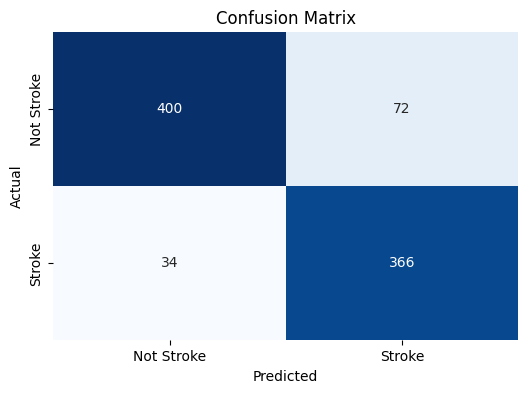


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.92      0.85      0.88       472
      Stroke       0.84      0.92      0.87       400

    accuracy                           0.88       872
   macro avg       0.88      0.88      0.88       872
weighted avg       0.88      0.88      0.88       872

ROC-AUC: 0.9352012711864407


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


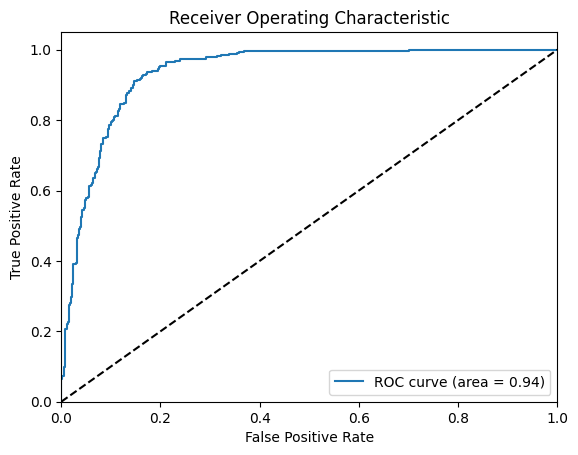

PR AUC: 0.9004914837417479


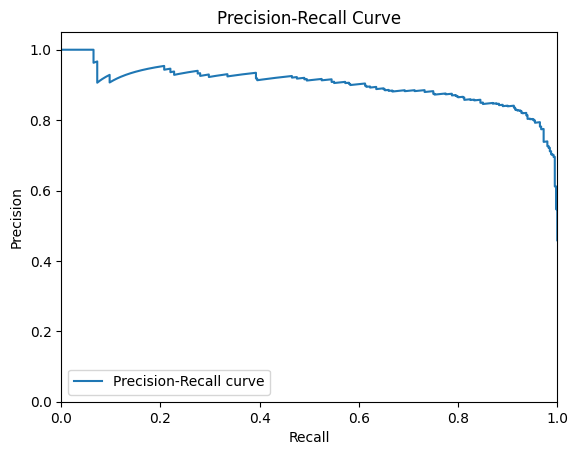

100%|██████████| 13/13 [00:35<00:00,  2.72s/it]


In [ ]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [23:04:57] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[397  75]
 [ 47 353]]


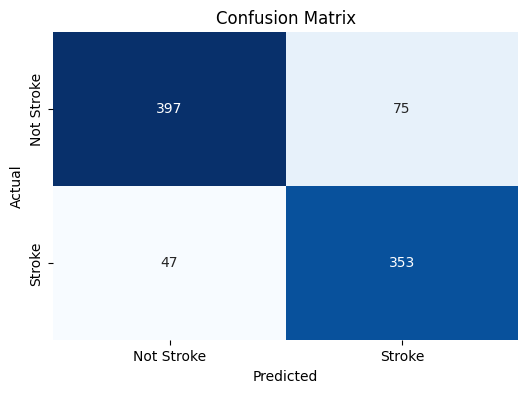


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.84      0.87       472
      Stroke       0.82      0.88      0.85       400

    accuracy                           0.86       872
   macro avg       0.86      0.86      0.86       872
weighted avg       0.86      0.86      0.86       872

ROC-AUC: 0.9179713983050848


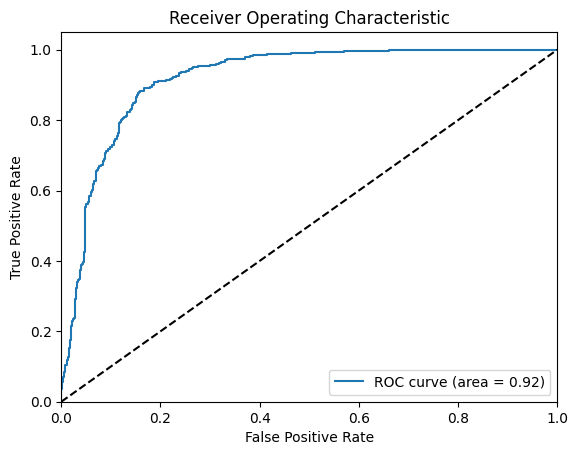

PR AUC: 0.8718029196695901


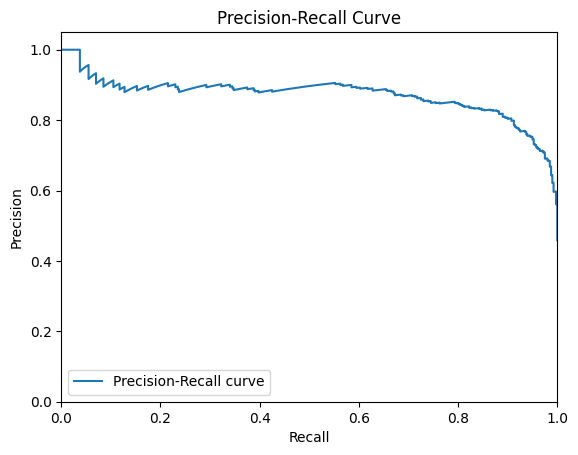

In [ ]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(x_train, y_train)
voting_train_pred = voting_model.predict(x_train)
voting_test_pred = voting_model.predict(x_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [23:05:05] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Confusion Matrix:
 [[390  82]
 [ 40 360]]


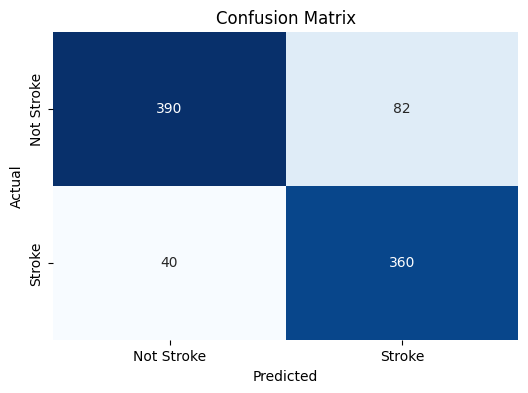


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.83      0.86       472
      Stroke       0.81      0.90      0.86       400

    accuracy                           0.86       872
   macro avg       0.86      0.86      0.86       872
weighted avg       0.86      0.86      0.86       872

ROC-AUC: 0.9205137711864407


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


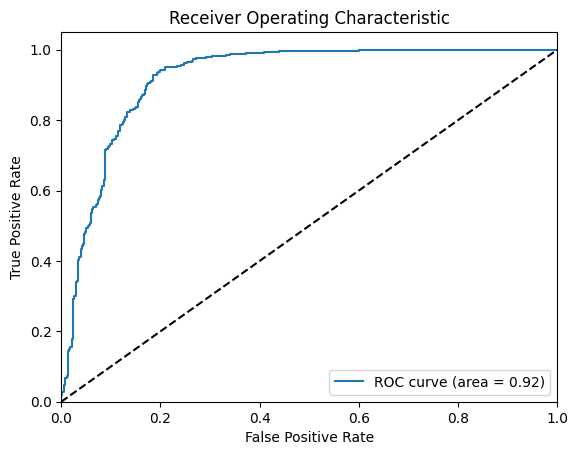

PR AUC: 0.8647394796065987


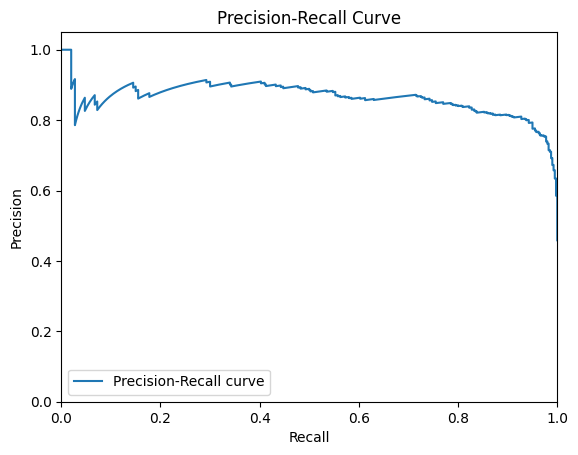

In [ ]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(x_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(x_train)
stack_auto_test_pred  = stack_auto.predict(x_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
CatBoost,0.911176,0.879587,0.886703,0.839080,0.927318,0.9125,0.906556,0.874251,0.912242,0.882097,0.937156,0.896275
LightGBM,0.912960,0.878440,0.878610,0.835616,0.942951,0.9150,0.909644,0.873508,0.914941,0.881229,0.935201,0.900491
Hist Gradient Boosting,0.908500,0.872706,0.876156,0.830664,0.935272,0.9075,0.904749,0.867384,0.910268,0.875360,0.932738,0.894456
XGBoost,0.970817,0.869266,0.963385,0.827982,0.974218,0.9025,0.968771,0.863636,0.971042,0.871801,0.929147,0.881073
Random Forest,1.000000,0.860092,1.000000,0.814480,1.000000,0.9000,1.000000,0.855107,1.000000,0.863136,0.930800,0.884342
Stacking Classifier,0.884542,0.860092,0.839445,0.814480,0.929238,0.9000,0.882062,0.855107,0.887494,0.863136,0.920514,0.864739
Voting Classifier,0.921754,0.860092,0.894997,0.824766,0.942128,0.8825,0.917958,0.852657,0.923099,0.861801,0.917971,0.871803
Extra Trees,1.000000,0.858945,1.000000,0.833735,1.000000,0.8650,1.000000,0.849080,1.000000,0.859407,0.918946,0.865327
Gradient Boosting,0.850898,0.852064,0.823576,0.807256,0.864235,0.8900,0.843415,0.846611,0.851779,0.854958,0.923067,0.876170
SVC,0.836243,0.810780,0.806226,0.767654,0.852441,0.8425,0.828690,0.803337,0.837313,0.813199,0.897564,0.845837


<Axes: >

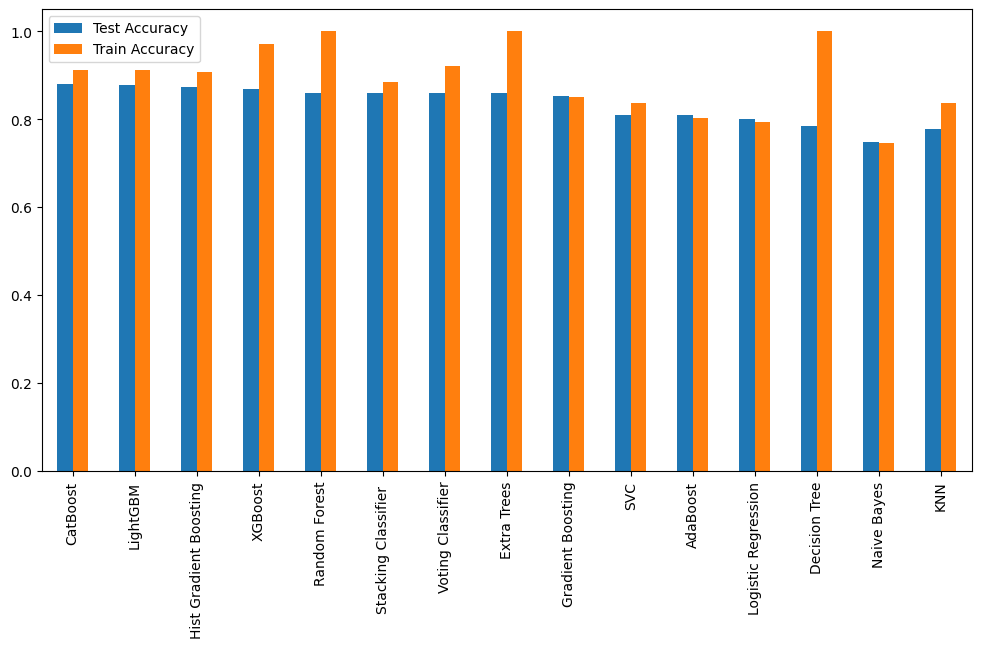

In [ ]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

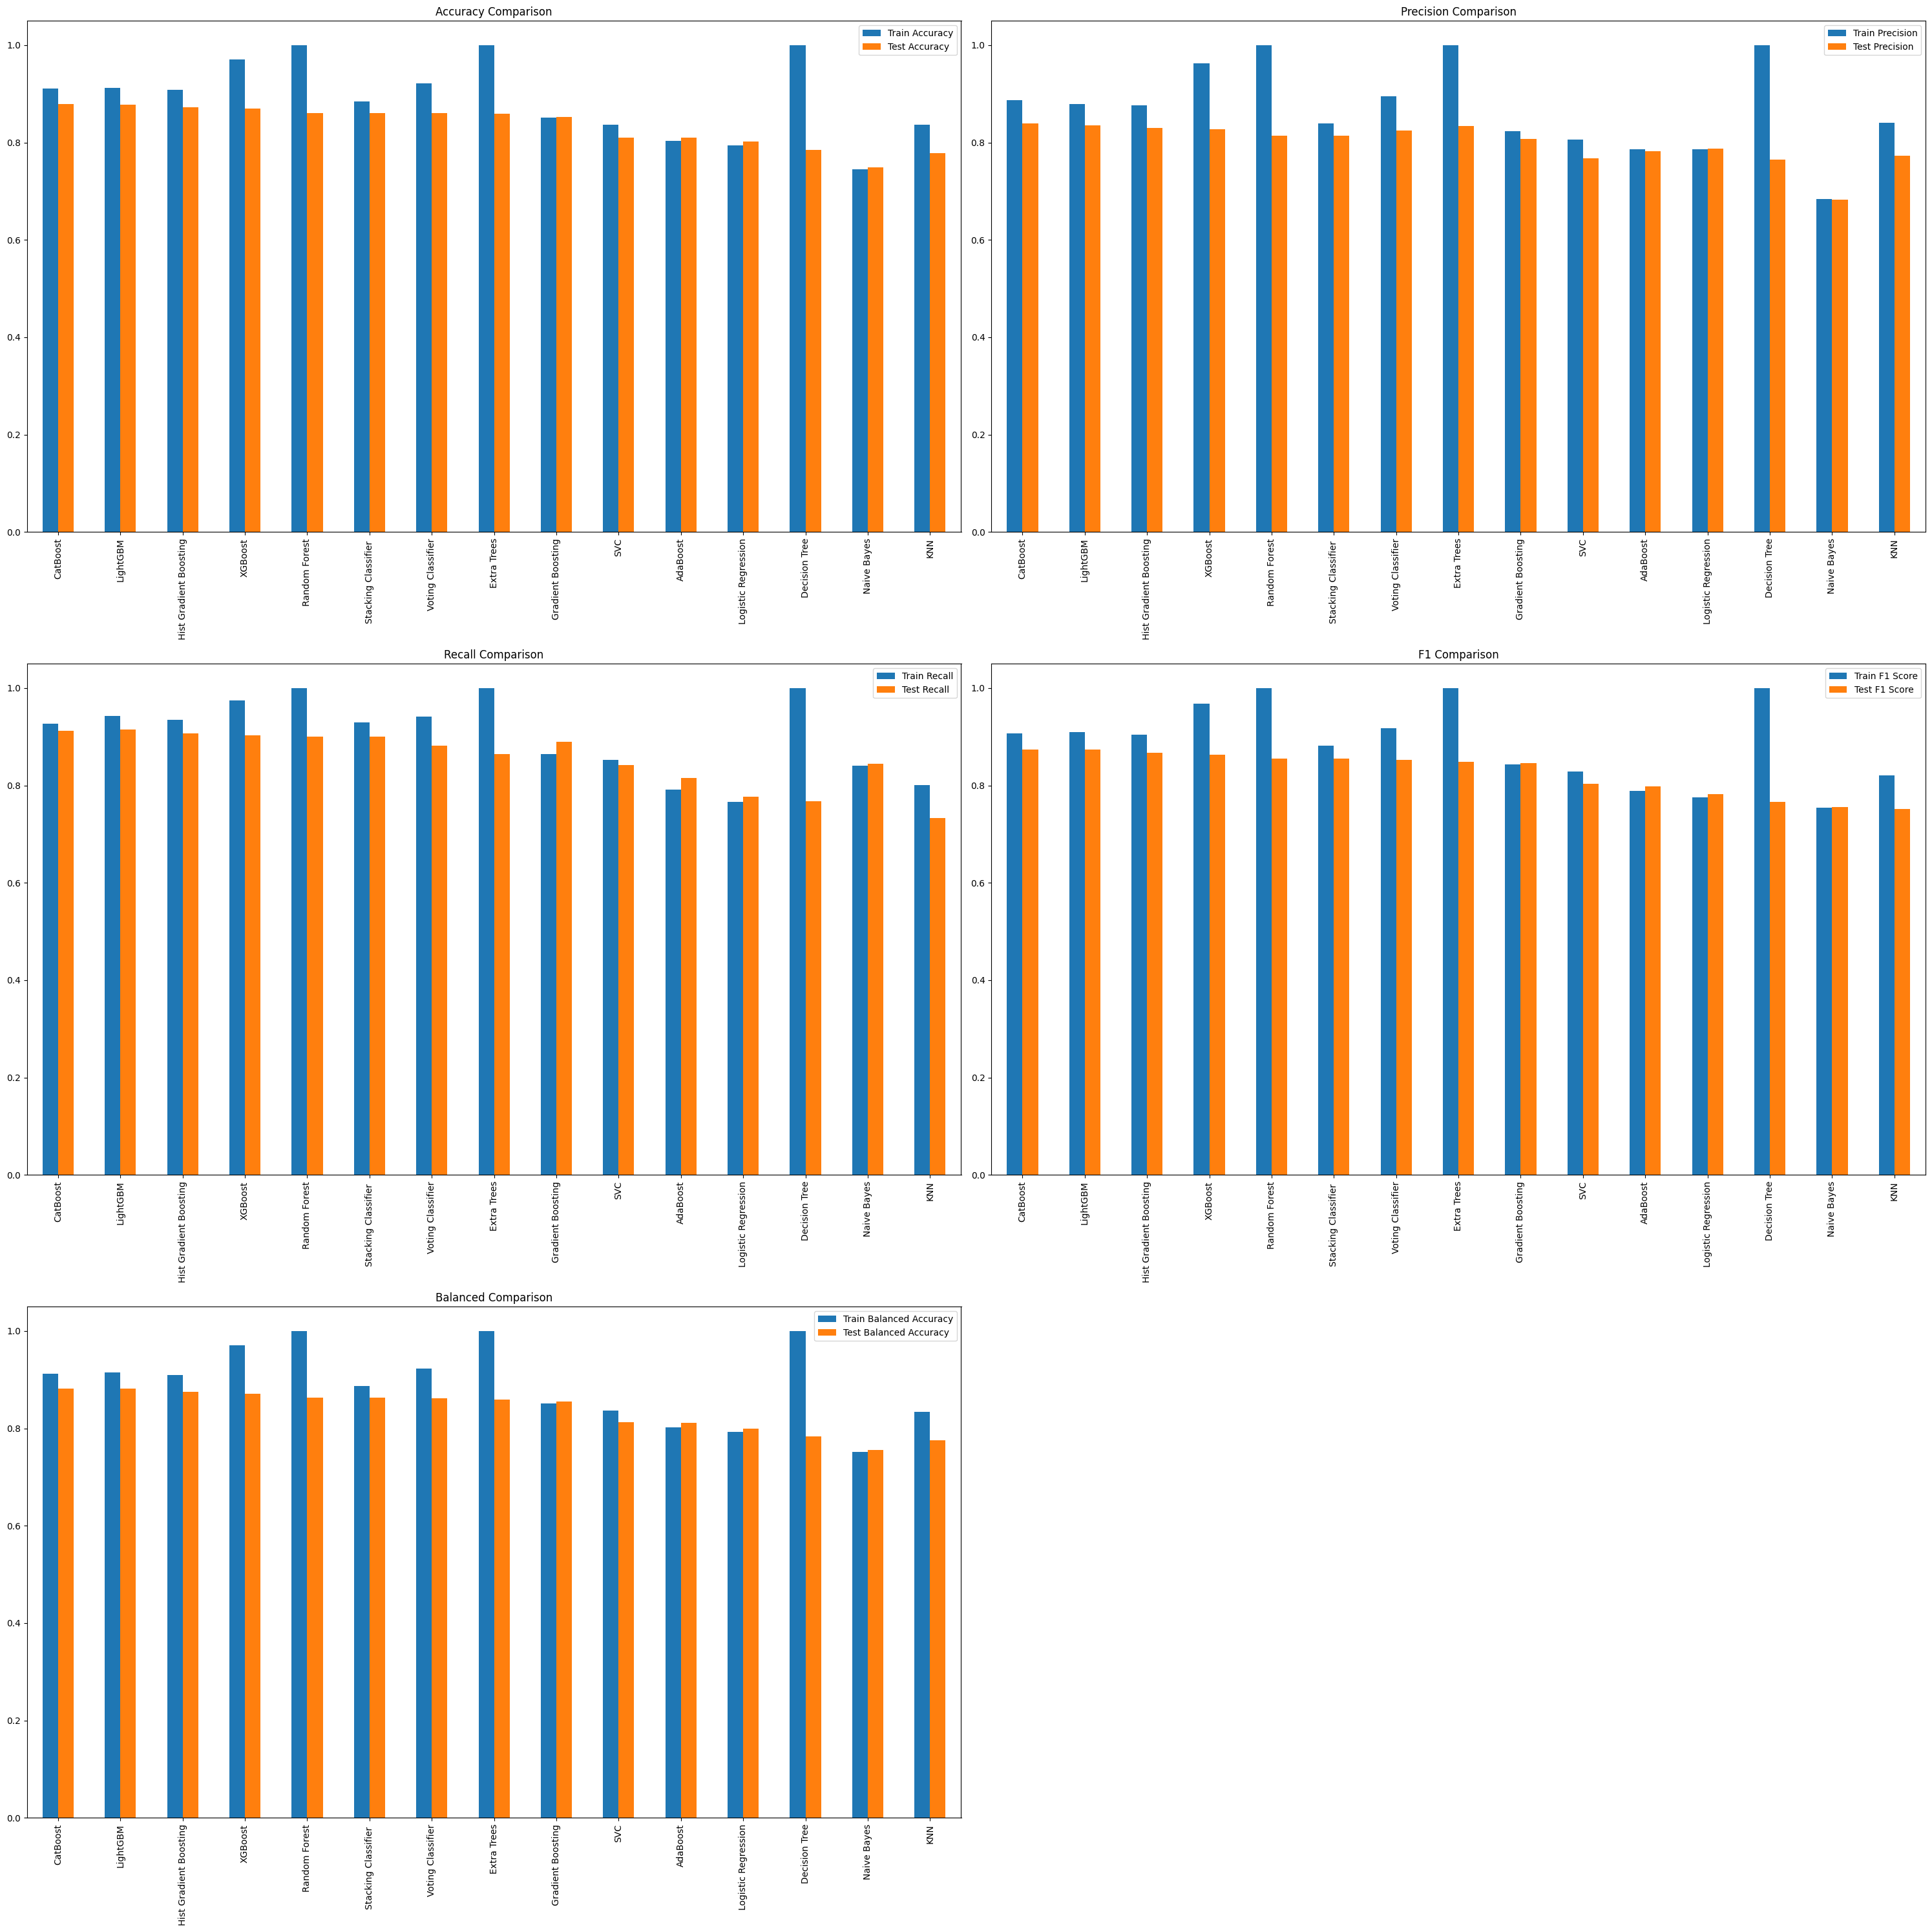

In [ ]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()